# Signal chain: from samples to RINEX

A recording of a GPS signal looks like noise. A receiver finds each satellite's repeating
code in that noise, follows the code's timing and the carrier under it, reads the message
the satellite broadcasts, and turns what it has followed into measurements. That sequence
is the signal chain. This notebook walks it with `pyrx`, the Python receiver of Purple
GNSS, from stored radio samples to two RINEX files: one of observations (pseudorange,
carrier phase, Doppler and signal strength) and one of navigation data (each satellite's
clock and orbit parameters). RINEX is the plain-text format in which receivers and
positioning software exchange such data.

Start here if you are new to GNSS. Basic Python and arrays are enough to follow the code;
familiarity with frequency and correlation helps with the first figures. The
[glossary](../../docs/fundamentals/glossary.md) defines the terms, and the shared
[notation](README.md#notation) lists the symbols and units. Each equation here also
defines the quantities it uses.

The real-data example is a 30 s GPS L1 C/A recording made in Japan on 2021-12-26, sampled
at 24 MHz with a 6 MHz intermediate frequency. Notebook 02 does not read this notebook's
output: on the capture path it computes positions from separate station files in the same
formats.

The committed outputs use the recording. The first code cell prints which data path is
active, and [data paths](README.md#data-paths) explains the capture setup and the
synthetic fallback. Synthetic data: the notebook generates 22 s of four GPS signals and
skips the comparison with Pocket SDR.

In [1]:
import dataclasses
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from scipy.signal import welch
from support import (
    data_source,
    diagram_arrow,
    diagram_box,
    diagram_canvas,
    diagram_label,
    diagram_line,
    diagram_text,
    figure,
    read_ctrk_log,
    read_trk_log,
    scratch_dir,
    synthetic_recording,
    threshold_line,
)

from pyrx.acquisition import DETECT_THRESHOLD, acquire_l1ca
from pyrx.codes import CA_CHIP_RATE
from pyrx.navdecode import decode_lnav
from pyrx.observables import code_starts, make_observables, transmit_times
from pyrx.plots import BAR, BAR_DETECTED, HIGHLIGHT, INK, LINES, MUTED, acquisition_figure
from pyrx.rinex import read_rinex_nav, write_rinex_nav, write_rinex_obs
from pyrx.samples import read_samples
from pyrx.synth import ephemeris as synthetic_ephemeris
from pyrx.tracking import T_FLL_PULLIN, track_channels

# generated samples and the RINEX files written here go to a temporary directory
out = scratch_dir("01-signal-chain")
src = data_source()
if src is not None:
    path, fs, f_if, iq = src.recording, src.fs, src.f_if, src.iq
else:
    path, fs, f_if, iq, _ = synthetic_recording(out)
print(f"{path.name}: {fs / 1e6:g} MHz {'I/Q' if iq else 'real'} samples, IF {f_if / 1e6:g} MHz")

running on the recordings named by PYRX_CAPTURES
L1_20211226_082401_24MHz_I.bin: 24 MHz real samples, IF 6 MHz


The map below is the whole chain. The antenna and the radio front-end are hardware outside
`pyrx`; the software starts at the recording. Acquisition and tracking both read the
samples: acquisition finds each satellite's code offset and Doppler, and tracking starts
from those and follows the signal. Tracking supplies the measurements; the navigation
decoder supplies their time tags and the ephemerides. The two RINEX files are what the
positioning stages read, and RTK also needs a second receiver, the base, at a surveyed
position.

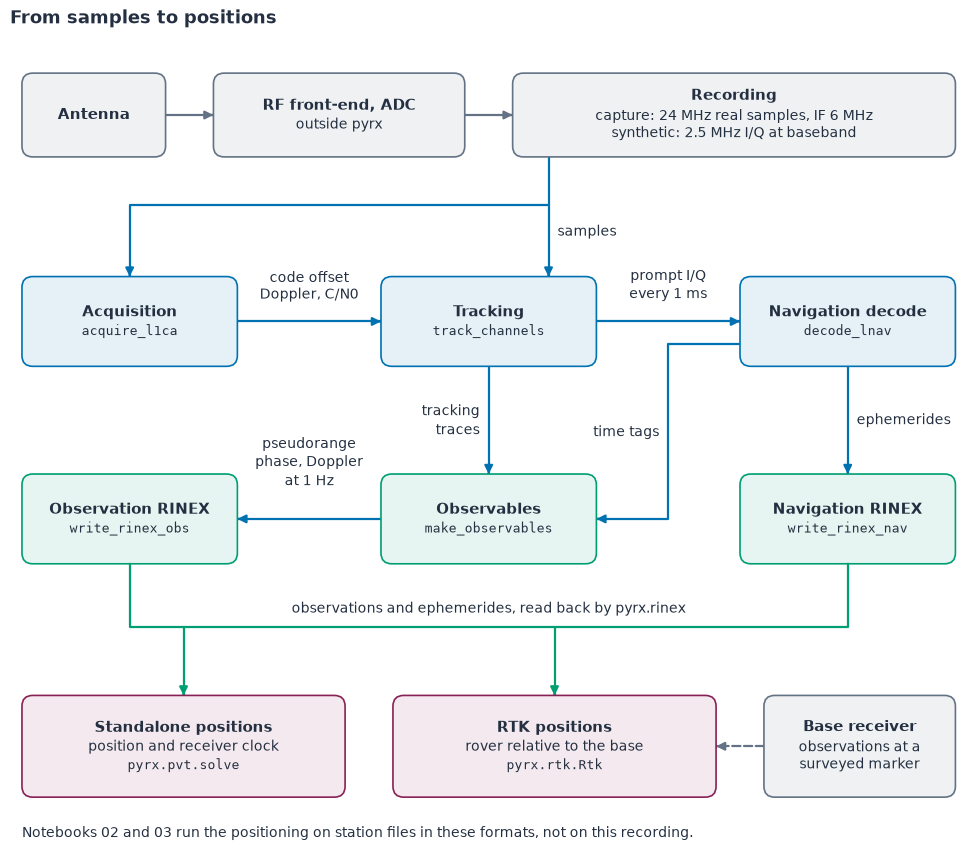

In [2]:
fig, ax = diagram_canvas(16, 13.6, "From samples to positions")
antenna = diagram_box(ax, 0.2, 11.6, 2.4, 1.4, "Antenna", role="context")
front = diagram_box(ax, 3.4, 11.6, 4.2, 1.4, "RF front-end, ADC", "outside pyrx", role="context")
rec = diagram_box(
    ax, 8.4, 11.6, 7.4, 1.4, "Recording",
    "capture: 24 MHz real samples, IF 6 MHz\nsynthetic: 2.5 MHz I/Q at baseband",
    role="context",
)  # fmt: skip
diagram_arrow(ax, [antenna.right, front.left], role="context")
diagram_arrow(ax, [front.right, rec.left], role="context")

acq = diagram_box(ax, 0.2, 8.1, 3.6, 1.5, "Acquisition", code="acquire_l1ca")
trk = diagram_box(ax, 6.2, 8.1, 3.6, 1.5, "Tracking", code="track_channels")
nav = diagram_box(ax, 12.2, 8.1, 3.6, 1.5, "Navigation decode", code="decode_lnav")
diagram_arrow(ax, [(9.0, rec.y), (9.0, trk.y + trk.height)], "samples", (9.15, 10.35), ha="left")
diagram_arrow(ax, [(9.0, 10.8), (2.0, 10.8), (2.0, acq.y + acq.height)])
diagram_arrow(ax, [acq.right, trk.left], "code offset\nDoppler, C/N0", (5.0, 9.45))
diagram_arrow(ax, [trk.right, nav.left], "prompt I/Q\nevery 1 ms", (11.0, 9.45))

obs = diagram_box(ax, 6.2, 4.8, 3.6, 1.5, "Observables", code="make_observables", role="measure")
obs_rnx = diagram_box(
    ax, 0.2, 4.8, 3.6, 1.5, "Observation RINEX", code="write_rinex_obs", role="measure"
)
nav_rnx = diagram_box(
    ax, 12.2, 4.8, 3.6, 1.5, "Navigation RINEX", code="write_rinex_nav", role="measure"
)
diagram_arrow(ax, [trk.bottom, obs.top], "tracking\ntraces", (7.85, 7.2), ha="right")
diagram_arrow(
    ax, [nav.at(0, 0.25), (11.0, nav.at(0, 0.25)[1]), (11.0, 5.55), obs.right],
    "time tags", (10.85, 7.0), ha="right",
)  # fmt: skip
diagram_arrow(
    ax, [(14.0, nav.y), (14.0, nav_rnx.y + nav_rnx.height)], "ephemerides", (14.15, 7.2), ha="left"
)
diagram_arrow(ax, [obs.left, obs_rnx.right], "pseudorange\nphase, Doppler\nat 1 Hz", (5.0, 6.5))

# both positioning stages read the two file types back through pyrx.rinex
bus = 3.75
diagram_line(ax, [obs_rnx.bottom, (2.0, bus), (14.0, bus), nav_rnx.bottom], role="measure", width=1.6)
diagram_label(ax, 8.0, bus + 0.3, "observations and ephemerides, read back by pyrx.rinex")
pvt = diagram_box(
    ax, 0.2, 0.9, 5.4, 1.7, "Standalone positions", "position and receiver clock",
    code="pyrx.pvt.solve", role="position",
)  # fmt: skip
rtk = diagram_box(
    ax, 6.4, 0.9, 5.4, 1.7, "RTK positions", "rover relative to the base",
    code="pyrx.rtk.Rtk", role="position",
)  # fmt: skip
base = diagram_box(
    ax, 12.6, 0.9, 3.2, 1.7, "Base receiver", "observations at a\nsurveyed marker",
    role="context",
)  # fmt: skip
diagram_arrow(ax, [(2.9, bus), (2.9, pvt.y + pvt.height)], role="measure")
diagram_arrow(ax, [(9.1, bus), (9.1, rtk.y + rtk.height)], role="measure")
diagram_arrow(ax, [base.left, rtk.right], role="context", dashed=True)
diagram_text(
    ax, 0.2, 0.3,
    "Notebooks 02 and 03 run the positioning on station files in these formats, "
    "not on this recording.",
    size=10, ha="left",
)  # fmt: skip
plt.show()

## 1. The recording

The radio front-end filters the antenna signal, shifts it down to an intermediate
frequency (IF) and samples it. In the committed recording the sample rate is 24 MHz and
the IF is 6 MHz. Each real sample occupies one signed byte, but the histogram shows only
four values, −3, −1, +1 and +3: four quantization levels, enough to carry the sign of
the signal and a coarse magnitude.

The satellite signals are far weaker than the noise, so a short stretch of samples shows
nothing by eye. What the coarse samples keep is a faint pattern of signs that repeats
with each satellite's code, and correlating over many samples brings it out.

Signal strength is reported as the carrier-to-noise density ratio, C/N0, in dB-Hz: the
carrier power divided by the noise power in one hertz of bandwidth. To compare the
carrier with the noise in a bandwidth $B$ (in hertz), subtract $10\log_{10}B$:

$$
(C/N)_{\rm dB}=(C/N_0)_{\rm dB\text{-}Hz}-10\log_{10}B .
$$

On the recording, the front-end's passband in the spectrum below spans roughly 4 to 8 MHz,
about 4 MHz, and
$10\log_{10}(4\times10^6)\approx 66$ dB, so the seven satellites detected in the next
section, at 39.0 to 48.7 dB-Hz, sit roughly 17 to 27 dB below the noise in that band.

The plots use the first 0.1 s. The spectrum is filtered noise around the IF; no single
satellite shows in it. A real-valued signal has a mirror-image spectrum at negative
frequencies, so only the positive half is drawn.

The narrow spikes on the recording's curve are not satellites either. Those at 2.58, 8.58
and 9.42 MHz are harmonics of the front-end's own clock that leak into its input and are
mixed down with the signal.

Synthetic data: the generated recording is at complex baseband. The IF is zero, the
sample rate 2.5 MHz, and each sample is two signed bytes, in-phase (I) and quadrature
(Q), with white noise and many more than four levels. The time slice
shows at least 16 samples, 6.4 µs on this path
against 2 µs on the recording.

Read more: [From antenna to samples](../../docs/fundamentals/03-antenna-to-samples.md).

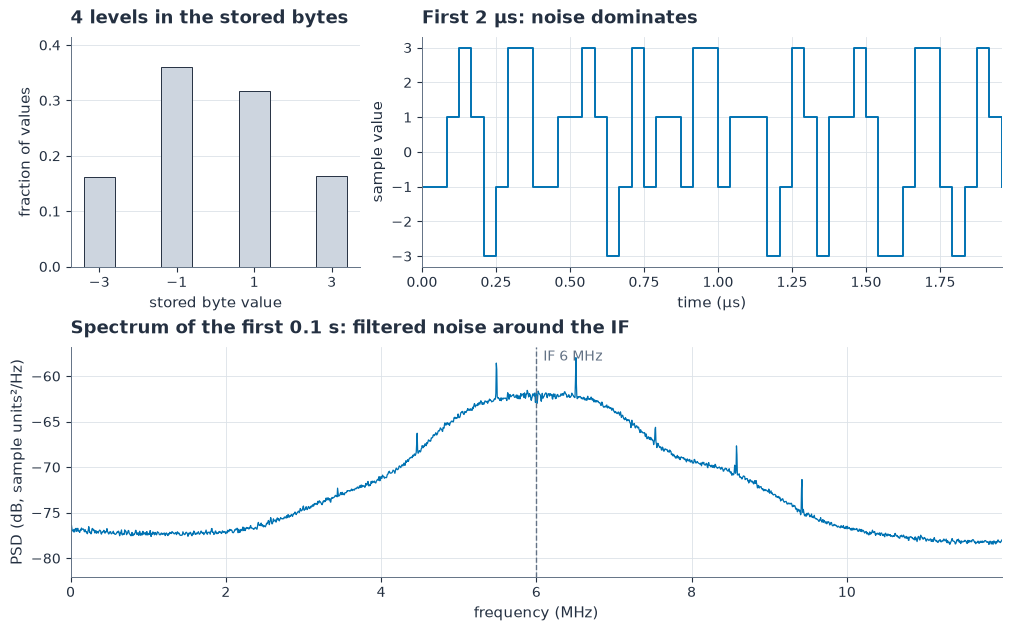

In [3]:
bytes_per_sample = 2 if iq else 1  # an I/Q sample is two interleaved bytes
raw = np.fromfile(path, dtype=np.int8, count=int(fs * 0.1) * bytes_per_sample)
x = read_samples(path, fs, iq, 0.0, 0.1)
levels, counts = np.unique(raw, return_counts=True)
n_slice = max(int(2e-6 * fs), 16)  # at least 16 samples, so the synthetic slice is readable
# a display spectrum of the 0.1 s, not a receiver stage; real samples need only one half
f, pxx = welch(x, fs, nperseg=4096, return_onesided=False)
f, pxx = np.fft.fftshift(f), np.fft.fftshift(pxx)
if not iq:
    f, pxx = f[f >= 0], pxx[f >= 0]
psd = 10 * np.log10(pxx)

fig, axes = figure(2, 2, figsize=(10, 6.2), gridspec_kw={"width_ratios": [1, 2]})
gs = axes[1, 0].get_gridspec()
for ax in axes[1]:
    ax.remove()
ax_h, ax_t = axes[0]
ax_s = fig.add_subplot(gs[1, :])

share = counts / counts.sum()
ax_h.bar(levels, share, color=BAR, edgecolor=INK, linewidth=0.7, width=0.8)
if len(levels) <= 8:
    ax_h.set_xticks(levels)
else:
    ax_h.xaxis.set_major_locator(MaxNLocator(6, integer=True))
ax_h.set(ylim=(0, share.max() * 1.15), xlabel="stored byte value", ylabel="fraction of values")
ax_h.grid(axis="x", visible=False)
ax_h.set_title(f"{len(levels)} levels in the stored bytes")

t_us = np.arange(n_slice) / fs * 1e6
ax_t.step(t_us, x[:n_slice].real, where="post", color=LINES[0], linestyle="-", label="I")
if iq:
    ax_t.step(t_us, x[:n_slice].imag, where="post", color=LINES[1], linestyle="--", label="Q")
    ax_t.legend(loc="upper right", ncol=2)
ax_t.set(xlim=(0, t_us[-1]), xlabel="time (µs)", ylabel="sample value")
ax_t.set_title(f"First {n_slice / fs * 1e6:g} µs: noise dominates")

ax_s.plot(f / 1e6, psd, color=LINES[0], linestyle="-", linewidth=0.9)
ax_s.axvline(f_if / 1e6, color=MUTED, linestyle="--", linewidth=1)
ax_s.annotate(f"IF {f_if / 1e6:g} MHz", (f_if / 1e6, 1.0), xycoords=("data", "axes fraction"),
              xytext=(5, -2), textcoords="offset points", va="top", fontsize=10, color=MUTED)
ax_s.set(xlim=(f[0] / 1e6, f[-1] / 1e6), xlabel="frequency (MHz)",
         ylabel="PSD (dB, sample units²/Hz)")  # fmt: skip
ax_s.set_title("Spectrum of the first 0.1 s: filtered noise"
               + (" around the IF" if not iq else " at complex baseband"))  # fmt: skip
plt.show()

## 2. Acquisition

Each satellite transmits a known spreading code: a sequence of +1 and −1 chips that
repeats every 1 ms. The GPS L1 C/A code has 1023 chips, sent at 1.023 million chips per
second, and a PRN number says which of the 32 codes to generate.

Correlation asks whether a shifted copy of that code is present. Multiply the samples by
the code, chip by chip, and add the products. When the code and its shift match, the
products add up consistently; noise adds with random signs and largely cancels; a wrong
shift or another satellite's code gives a much smaller sum. The carrier frequency has to
be searched as well, because the satellite's motion and the receiver oscillator's error
move the received frequency by up to a few kilohertz.

The search uses the first 10 ms of samples. Let $f_s$ be the sample rate, $T = 1$ ms the
code period, $N = f_sT$ the number of samples in one period, $x$ the samples and $c$ the
code sampled at $f_s$. Let $l$ number the ten 1 ms blocks, $m$ be a trial code offset in
samples, $f$ a trial Doppler in hertz and $f_{\rm IF}$ the IF. The correlation of block
$l$ is

$$
R_l(f,m)=\sum_{k=0}^{N-1} x[lN+k]\,e^{-j2\pi(f_{\rm IF}+f)k/f_s}\,c[(k-m)\bmod N].
$$

The exponential removes a trial carrier and the shifted code removes a trial spreading
pattern. An FFT computes all $N$ values of $m$ at once. The ten blocks are then added as
powers:

$$
P(f,m)=\sum_{l=0}^{9}|R_l(f,m)|^2 .
$$

Adding powers instead of complex sums is called non-coherent integration. A change of
sign or phase between blocks, from a data bit or a small frequency error, cannot cancel
the total, although a sign change inside a block still weakens that block.

The trial Dopplers run from −5 kHz to +5 kHz in steps of $\Delta f = 0.5/T = 500$ Hz,
21 bins in all. A signal between two bins is at most 250 Hz from one of them, so its
residual phase turns by at most a quarter of a cycle over the 1 ms sum. One code period
holds 24 000 samples on the recording and 2500 on the synthetic path, so the grid for
one PRN has 21 × 24 000 or 21 × 2500 cells.

In the diagram, the top row takes one 1 ms block from samples to the correlation at every
code offset; the bottom row adds the powers of the ten blocks into one row of the search
grid. The 21 Doppler rows make the grid, and its peak is the detection.

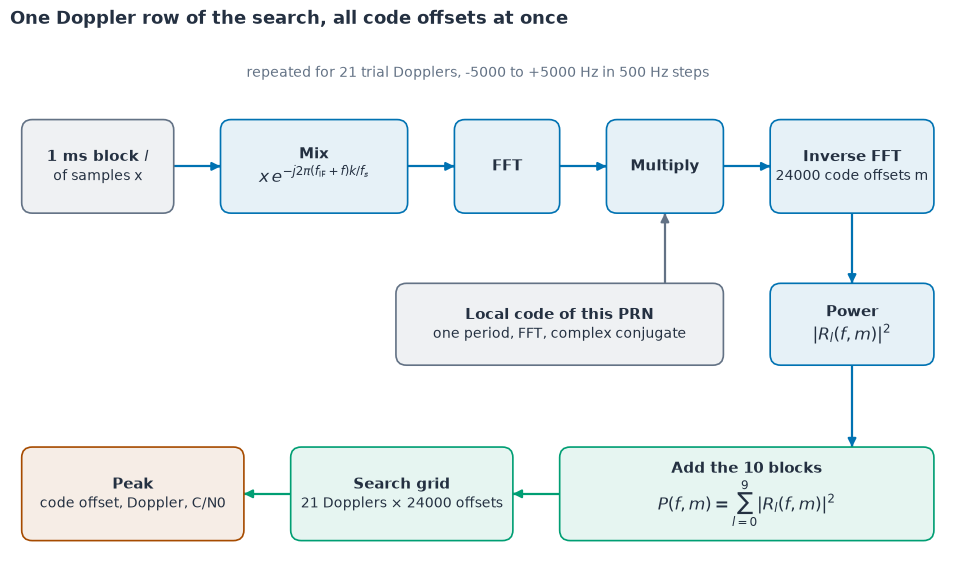

In [4]:
n_per_ms = round(fs * 1e-3)
fig, ax = diagram_canvas(16, 9.0, "One Doppler row of the search, all code offsets at once")
diagram_text(
    ax, 8.0, 8.4, "repeated for 21 trial Dopplers, -5000 to +5000 Hz in 500 Hz steps",
    size=10, color=MUTED,
)  # fmt: skip
block = diagram_box(ax, 0.2, 6.0, 2.6, 1.6, "1 ms block $l$", "of samples x", role="context")
mix = diagram_box(
    ax, 3.6, 6.0, 3.2, 1.6, "Mix", formula=r"$x\,e^{-j2\pi(f_{\rm IF}+f)k/f_s}$"
)
fft = diagram_box(ax, 7.6, 6.0, 1.8, 1.6, "FFT")
mult = diagram_box(ax, 10.2, 6.0, 2.0, 1.6, "Multiply")
ifft = diagram_box(ax, 13.0, 6.0, 2.8, 1.6, "Inverse FFT", f"{n_per_ms} code offsets m")
for a, b in ((block, mix), (mix, fft), (fft, mult), (mult, ifft)):
    diagram_arrow(ax, [a.right, b.left])
code = diagram_box(
    ax, 6.6, 3.4, 5.6, 1.4, "Local code of this PRN", "one period, FFT, complex conjugate",
    role="context",
)  # fmt: skip
diagram_arrow(ax, [(11.2, code.y + code.height), (11.2, mult.y)], role="context")
power = diagram_box(ax, 13.0, 3.4, 2.8, 1.4, "Power", formula=r"$|R_l(f,m)|^2$")
diagram_arrow(ax, [ifft.bottom, power.top])
total = diagram_box(
    ax, 9.4, 0.4, 6.4, 1.6, "Add the 10 blocks",
    formula=r"$P(f,m)=\sum_{l=0}^{9}|R_l(f,m)|^2$", role="measure",
)  # fmt: skip
diagram_arrow(ax, [power.bottom, (power.bottom[0], total.y + total.height)])
grid = diagram_box(
    ax, 4.8, 0.4, 3.8, 1.6, "Search grid", f"21 Dopplers × {n_per_ms} offsets", role="measure"
)
diagram_arrow(ax, [total.left, grid.right], role="measure")
peak = diagram_box(
    ax, 0.2, 0.4, 3.8, 1.6, "Peak", "code offset, Doppler, C/N0", role="highlight"
)
diagram_arrow(ax, [grid.left, peak.right], role="measure")
plt.show()

### Which satellites are present

The library estimates C/N0 from the search grid itself. Let $P_{\max}$ be the largest
grid power and $P_{\rm mean}$ the mean over the whole grid:

$$
\widehat{C/N_0}=10\log_{10}\frac{P_{\max}-P_{\rm mean}}{P_{\rm mean}\,T}\ \text{dB-Hz}.
$$

Subtracting the mean removes the noise's share of the peak, and dividing by $T$ turns a
ratio over a 1 ms integration into a density per hertz. A PRN whose estimate is at or
above 38 dB-Hz becomes a candidate for tracking. In the committed recording the PRNs whose
grid holds only noise come out a few dB lower, around 34 dB-Hz. A
false detection would occupy a tracking channel until its C/N0 fell below the tracker's
25 dB-Hz loss threshold.

The printed line lists each candidate with its first Doppler estimate. In the committed
recording seven PRNs pass. The next stage tracks the six strongest, so PRN 29, at
39.0 dB-Hz, does not appear in the tracking figures.

Read more: [Finding a satellite](../../docs/fundamentals/04-acquisition.md).

detected: PRN 4 (42.6 dB-Hz, +463 Hz), PRN 16 (46.1 dB-Hz, +696 Hz), PRN 18 (41.2 dB-Hz, +476 Hz), PRN 26 (48.7 dB-Hz, -1020 Hz), PRN 27 (46.3 dB-Hz, +2528 Hz), PRN 29 (39.0 dB-Hz, -3861 Hz), PRN 31 (47.4 dB-Hz, -2441 Hz)


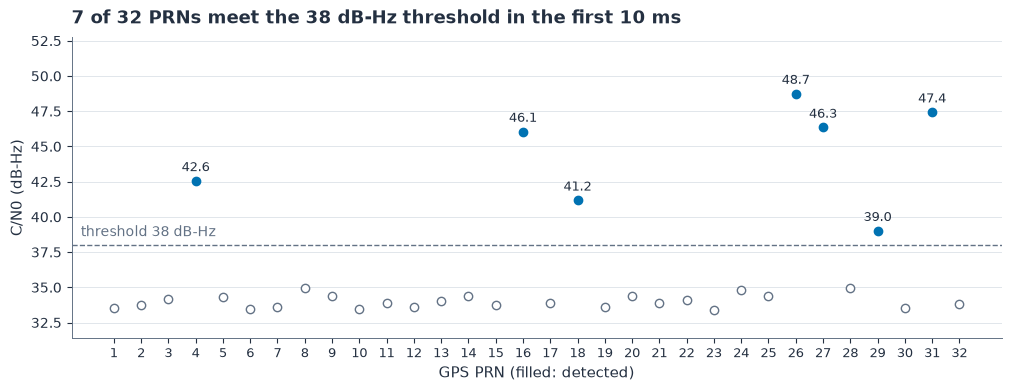

In [5]:
# the first 10 ms; acquire_l1ca adds the correlation powers of its ten 1 ms blocks
head = read_samples(path, fs, iq, 0.0, 0.010)
results = [acquire_l1ca(head, fs, f_if, prn) for prn in range(1, 33)]
# threshold crossings are tracking candidates, not yet tracked signals
detected = [r for r in results if r.detected]
best = max(results, key=lambda r: r.cn0)
print("detected:", ", ".join(f"PRN {r.prn} ({r.cn0:.1f} dB-Hz, {r.doppler:+.0f} Hz)"
                             for r in detected))  # fmt: skip

fig, ax = figure(figsize=(10, 3.8))
for i, r in enumerate(results):
    color = BAR_DETECTED if r.detected else MUTED
    face = color if r.detected else "white"
    ax.plot(i, r.cn0, "o", color=color, markerfacecolor=face, markersize=6, linestyle="none")
    if r.detected:
        ax.annotate(f"{r.cn0:.1f}", (i, r.cn0), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=9)  # fmt: skip
threshold_line(ax, DETECT_THRESHOLD, f"threshold {DETECT_THRESHOLD:g} dB-Hz")
cn0 = [r.cn0 for r in results]
low, high = min(*cn0, DETECT_THRESHOLD), max(*cn0, DETECT_THRESHOLD)
ax.set_ylim(low - 2, high + 4)
ax.set_xticks(range(len(results)), [str(r.prn) for r in results], fontsize=9)
ax.set(xlabel="GPS PRN (filled: detected)", ylabel="C/N0 (dB-Hz)")
ax.grid(axis="x", visible=False)
ax.set_title(f"{len(detected)} of {len(results)} PRNs meet the {DETECT_THRESHOLD:g} dB-Hz "
             "threshold in the first 10 ms")  # fmt: skip
plt.show()

### Reading the acquisition search

The four panels show the search grid of the strongest PRN. The same function draws the
`acq_prnNN.png` files of `pyrx-acq --plot`. The grid is divided by its largest power, so
the peak is 1, or 0 dB.

- Top left: at every code offset, the strongest of the 21 Doppler bins, in dB relative to
  the peak. Every one of the grid's columns is drawn, and one spike stands well clear of
  the noise floor. The offset is the time from the start of the 10 ms buffer to the
  start of a code period, reduced to one period. It says where the code starts in the
  buffer, which is not the signal's travel time from the satellite. In the committed
  recording PRN 26's code starts 0.1775 ms into the buffer.
- Top right: the cells within 3 chips of the peak, every Doppler bin, as a color map in
  dB. The match spans about one chip on either side of the peak, since the code stops
  matching itself once shifted by a chip. At 24 MHz a chip is about 23.5 samples, so the
  peak is many samples wide even though the offset is measured to one sample.
- Bottom left: the code cut through the peak, at the peak's Doppler bin: the triangle of a
  code correlating with itself, falling to the floor about one chip either side.
- Bottom right: the Doppler cut at the peak's code offset, the 21 sampled bins. A 1 ms
  coherent sum responds over a broad range of frequencies, so the bins next to the peak
  still hold a good fraction of its power (about 0.47 and 0.38 in the committed
  recording). The library fits a parabola through the strongest bin and its two
  neighbors (unless the maximum is at the edge of the search) and reports its vertex,
  the dashed line. The code offset is not refined between samples.

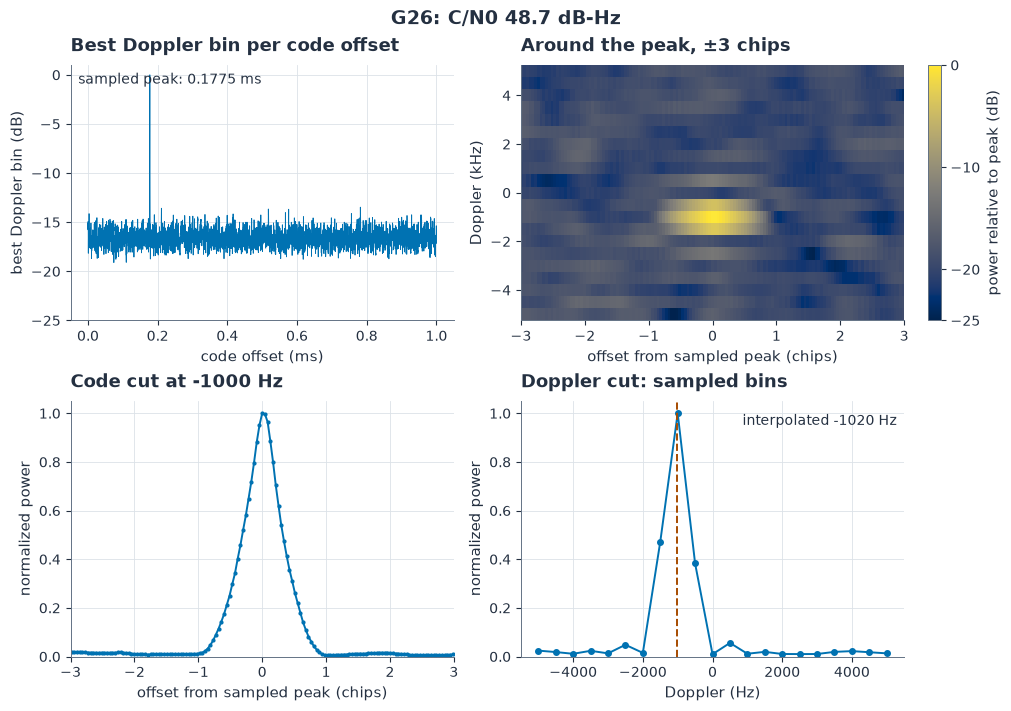

In [6]:
display(acquisition_figure(best, fs))

## 3. Tracking

Acquisition supplies a starting code offset and Doppler. A tracking channel then
correlates one code period at a time, measures how far its local copies of the code and
carrier (the replicas) are off, and corrects them. Each integration is a tracking epoch
of about 1 ms. The notebook tracks at most the six strongest candidates.

There are four correlator taps. Prompt uses the current code alignment; early and late
shift the code replica by +0.25 and −0.25 chip; a noise tap at −10 chips sits far from
the correlation peak and measures the noise. Each tap gives a complex sum. Write the
prompt sum at tracking epoch $k$ as $P_k = I_k + jQ_k$, with $I_k$ and $Q_k$ its real and
imaginary parts, the in-phase and quadrature components.

Samples run left to right across the top of the diagram, and the dashed arrows carry the
corrections back. The prompt sum steers the carrier, the early/late imbalance steers the
code, and the carrier's Doppler also sets the code's chip rate. Prompt and noise power
give the C/N0 that decides when a channel is lost.

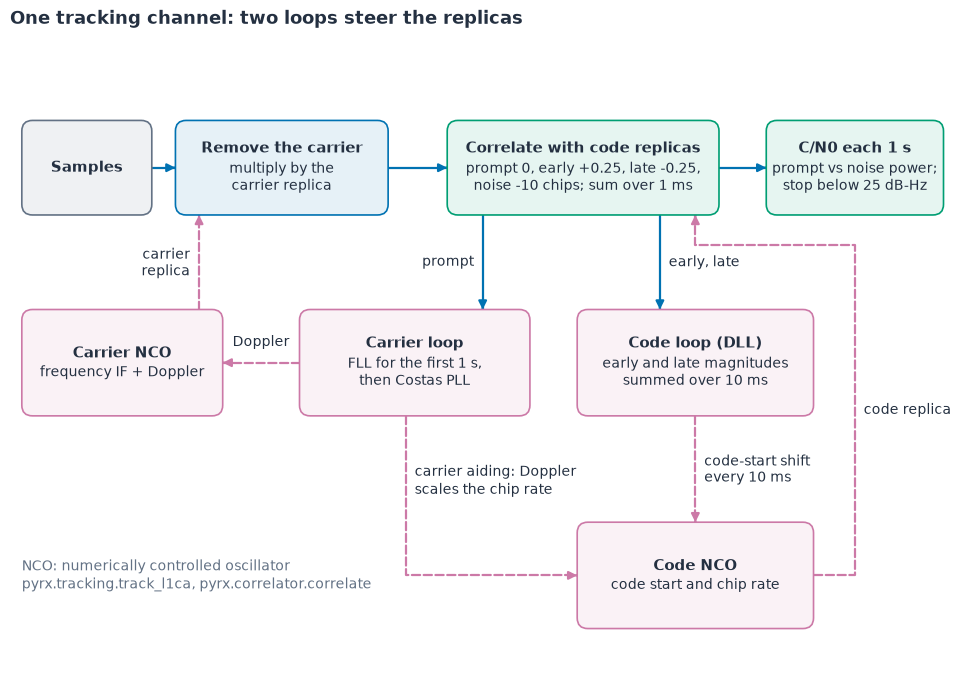

In [7]:
fig, ax = diagram_canvas(16, 10.6, "One tracking channel: two loops steer the replicas")
samples = diagram_box(ax, 0.2, 7.6, 2.2, 1.6, "Samples", role="context")
mix = diagram_box(ax, 2.8, 7.6, 3.6, 1.6, "Remove the carrier", "multiply by the\ncarrier replica")
corr = diagram_box(
    ax, 7.4, 7.6, 4.6, 1.6, "Correlate with code replicas",
    "prompt 0, early +0.25, late -0.25,\nnoise -10 chips; sum over 1 ms", role="measure",
)  # fmt: skip
cn0 = diagram_box(
    ax, 12.8, 7.6, 3.0, 1.6, "C/N0 each 1 s", "prompt vs noise power;\nstop below 25 dB-Hz",
    role="measure",
)  # fmt: skip
diagram_arrow(ax, [samples.right, mix.left])
diagram_arrow(ax, [mix.right, corr.left])
diagram_arrow(ax, [corr.right, cn0.left])

nco = diagram_box(ax, 0.2, 4.2, 3.4, 1.8, "Carrier NCO", "frequency IF + Doppler", role="control")
carrier = diagram_box(
    ax, 4.9, 4.2, 3.9, 1.8, "Carrier loop", "FLL for the first 1 s,\nthen Costas PLL",
    role="control",
)  # fmt: skip
dll = diagram_box(
    ax, 9.6, 4.2, 4.0, 1.8, "Code loop (DLL)", "early and late magnitudes\nsummed over 10 ms",
    role="control",
)  # fmt: skip
code_nco = diagram_box(
    ax, 9.6, 0.6, 4.0, 1.8, "Code NCO", "code start and chip rate", role="control"
)
diagram_arrow(ax, [(8.0, corr.y), (8.0, carrier.y + carrier.height)], "prompt", (7.85, 6.8),
              ha="right")  # fmt: skip
diagram_arrow(ax, [(11.0, corr.y), (11.0, dll.y + dll.height)], "early, late", (11.15, 6.8),
              ha="left")  # fmt: skip
diagram_arrow(ax, [carrier.left, nco.right], "Doppler", (4.25, 5.45), role="control")
diagram_arrow(
    ax, [(3.2, nco.y + nco.height), (3.2, mix.y)], "carrier\nreplica", (3.05, 6.8),
    role="control", ha="right",
)  # fmt: skip
diagram_arrow(ax, [dll.bottom, code_nco.top], "code-start shift\nevery 10 ms", (11.75, 3.3),
              role="control", ha="left")  # fmt: skip
diagram_arrow(
    ax, [(6.7, carrier.y), (6.7, 1.5), code_nco.left], "carrier aiding: Doppler\nscales the chip rate",
    (6.85, 3.1), role="control", ha="left",
)  # fmt: skip
diagram_arrow(
    ax, [code_nco.right, (14.3, 1.5), (14.3, 7.1), (11.6, 7.1), (11.6, corr.y)],
    "code replica", (14.45, 4.3), role="control", ha="left",
)  # fmt: skip
diagram_text(
    ax, 0.2, 1.5,
    "NCO: numerically controlled oscillator\npyrx.tracking.track_l1ca, pyrx.correlator.correlate",
    size=10, ha="left", color=MUTED,
)  # fmt: skip
plt.show()

### The carrier loops

The carrier needs the right frequency first. During the first 1 s a frequency-locked loop
(FLL) compares successive prompt sums. With $k-1$ the previous epoch, it forms

$$
\mathrm{dot}=I_kI_{k-1}+Q_kQ_{k-1},\qquad
\mathrm{cross}=I_kQ_{k-1}-Q_kI_{k-1},\qquad
e_F=\frac{1}{2\pi}\arctan\frac{\mathrm{cross}}{\mathrm{dot}} .
$$

$e_F$ is minus the change of the prompt's phase over one epoch, in cycles: cross is
proportional to the sine of the previous phase minus the current one.
A steady change from epoch to epoch means the replica's frequency is off, and the FLL corrects the Doppler by
a fraction of it. The FLL uses a loop bandwidth of 5 Hz for the first half of the
pull-in and 2 Hz for the second. The bandwidth sets how quickly a loop responds and how
much noise reaches its estimate.

After 1 s a second-order Costas phase-locked loop (PLL), with a 5 Hz bandwidth, takes
over. It uses the current prompt sum alone:

$$
e_P=\frac{1}{2\pi}\arctan\frac{Q_k}{I_k} .
$$

$e_P$ is the phase error in cycles. A navigation data bit that changes sign negates both
$I_k$ and $Q_k$ and leaves their ratio unchanged, so the loop follows the carrier straight
through the data. Both discriminators skip an epoch whose denominator is zero.

The two use opposite signs: $e_P$ is the prompt's phase itself, while $e_F$ is minus its
change. The channel figure below plots $-e_F$, the phase change itself, so that both
halves of its carrier panel count phase the same way.

### The code loop

Let $E_k$ and $L_k$ be the complex early and late sums. Over ten tracking epochs, sum
their magnitudes, $S_E=\sum|E_k|$ and $S_L=\sum|L_k|$. Every 10 ms the delay-locked loop
(DLL) forms

$$
e_{D,\mathrm{chips}}=\frac{S_E-S_L}{2(S_E+S_L)},\qquad
e_{D,\mathrm{s}}=\frac{e_{D,\mathrm{chips}}}{R_c},
$$

where $R_c$ is the C/A chip rate, 1.023 million chips per second. These are sums of
magnitudes. The library stores the second quantity, and the figure multiplies
it by $R_c$ to show chips. The DLL bandwidth is 0.25 Hz, and a zero denominator skips the
update.

Most of the code's motion never reaches the DLL. At each epoch the code replica runs at
the chip rate $R_c(1+f_D/f_{L1})$, where $f_D$ is the tracked Doppler and $f_{L1}$ =
1575.42 MHz, and the next code period starts $T(1-f_D/f_{L1})$ later. This is carrier
aiding: a 1 kHz Doppler compresses the code by $1000/1.57542\times10^9$, 0.63 parts per
million, which over 1 s moves the code by 0.63 µs, about 0.65 chip. The carrier loop
predicts that, and the slow DLL corrects only what is left.

The sketch shows why the sign of $S_E-S_L$ gives the direction of the correction. When the
replica is late (left), the early tap sits nearer the peak than the late one, and the
DLL moves the code start earlier; when it is early (right), the correction reverses.

Read more: [Staying locked](../../docs/fundamentals/05-tracking.md).

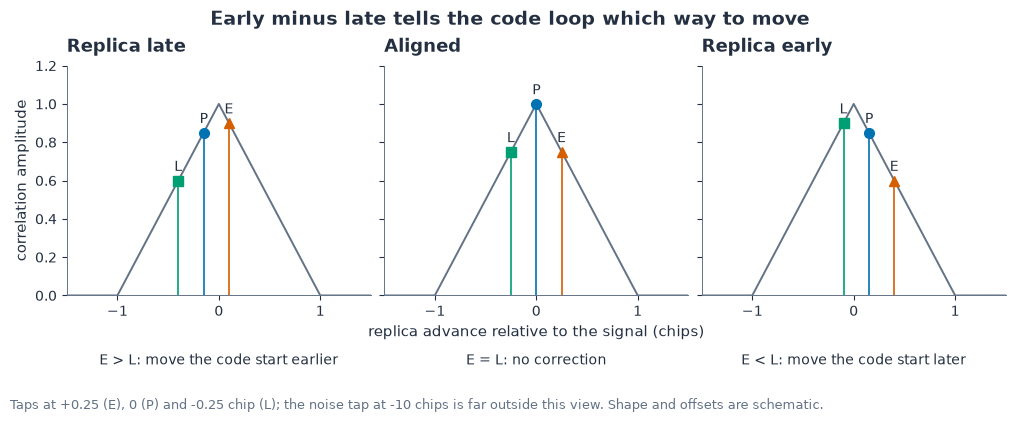

In [8]:
def lobe(x):
    # idealised correlation amplitude of a code against itself, one chip wide each side
    return np.clip(1 - np.abs(x), 0, None)


fig, axes = figure(1, 3, figsize=(10, 3.6), sharey=True)
cases = (
    ("Replica late", -0.15, "E > L: move the code start earlier"),
    ("Aligned", 0.0, "E = L: no correction"),
    ("Replica early", 0.15, "E < L: move the code start later"),
)
x = np.linspace(-1.5, 1.5, 301)
for ax, (title, prompt_at, verdict) in zip(axes, cases):
    ax.plot(x, lobe(x), color=MUTED, linewidth=1.4)
    for name, tap, color, marker in (
        ("E", 0.25, LINES[1], "^"),
        ("P", 0.0, LINES[0], "o"),
        ("L", -0.25, LINES[2], "s"),
    ):
        at = prompt_at + tap
        ax.vlines(at, 0, lobe(at), color=color, linewidth=1.2)
        ax.plot(at, lobe(at), marker, color=color, markersize=7, linestyle="none")
        ax.annotate(name, (at, lobe(at)), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=10)  # fmt: skip
    ax.set_title(title)
    ax.text(0.5, -0.3, verdict, transform=ax.transAxes, ha="center", fontsize=10)
    ax.set(xlim=(-1.5, 1.5), ylim=(0, 1.2), xticks=[-1, 0, 1])
    ax.grid(False)
fig.suptitle("Early minus late tells the code loop which way to move")
axes[1].set_xlabel("replica advance relative to the signal (chips)")
axes[0].set_ylabel("correlation amplitude")
fig.text(
    0.0, -0.12, "Taps at +0.25 (E), 0 (P) and -0.25 chip (L); the noise tap at -10 chips is far "
    "outside this view. Shape and offsets are schematic.", fontsize=9, color=MUTED,
)  # fmt: skip
plt.show()

### One channel settling

The figure follows the strongest channel over its first 3.6 s. The strip at the top says
which carrier loop is running: the FLL at 5 Hz, at 2 Hz from 0.5 s, then the Costas PLL
from 1 s. It also marks where the message decoder of section 4 starts: it uses prompt
signs from 1.5 s on and judges bit edges in 2 s windows. The loop schedule counts tracking
epochs, so the strip's boundaries are nominal times: an epoch lasts one Doppler-scaled code
period, which differs from 1 ms by less than a part per million.

Once the phase is locked, the prompt sums form two clouds near $+I$ and $-I$ (left, after
2 s). They are the two signs of the navigation data. A bit lasts 20 ms; the sign may
change at a bit boundary, and equal consecutive bits keep it. The spread in $Q$ is noise
and the remaining phase error.

In the committed recording the data signs are already visible during the FLL pull-in. The
FLL steers only the frequency and leaves the carrier at whatever phase offset it reaches:
late in the pull-in, prompt I sits near ±2700 instead of the ±4700 it reaches after the
handover, an offset of roughly 0.15 cycle ($\cos(2\pi\times0.15)\approx0.59$, close to
2700/4700). When the PLL takes over at 1 s it starts from that offset, the −0.15 cycle
step at the dashed line in the carrier panel, and pulls it to zero within a few hundred
milliseconds.

The two right-hand discriminator panels show the loops settling. The carrier panel
changes quantity at the handover: the phase change per 1 ms epoch ($-e_F$) before it, the
phase error ($e_P$) after it, both in cycles.
The code panel has one point per 10 ms DLL update, in chips.

The printed time is the computation time, not the recording length. `locked=True`
means the channel was not stopped by the C/N0 loss threshold.

tracked 6 channels in 31 s
tracked PRNs: 26 (locked=True), 31 (locked=True), 27 (locked=True), 16 (locked=True), 4 (locked=True), 18 (locked=True)


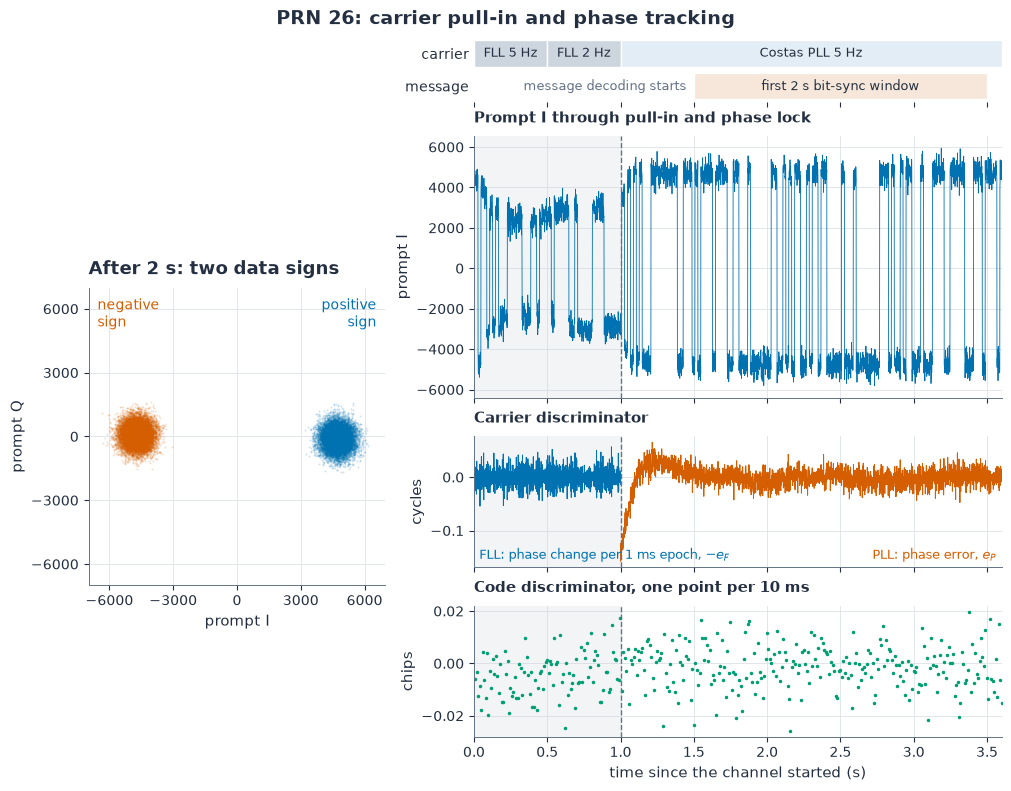

In [9]:
# (PRN, code offset in s, Doppler in Hz, C/N0 in dB-Hz) of the six strongest candidates
seeds = [(r.prn, r.code_offset, r.doppler, r.cn0)
         for r in sorted(detected, key=lambda r: -r.cn0)[:6]]  # fmt: skip
if not seeds:
    raise SystemExit("no PRN detected: nothing to track")
t0 = time.perf_counter()
tracks = track_channels(path, fs, iq, f_if, seeds)
print(f"tracked {len(tracks)} channels in {time.perf_counter() - t0:.0f} s")
print("tracked PRNs:", ", ".join(f"{tr.prn} (locked={tr.locked})" for tr in tracks))
track = tracks[0]
prompt = track.corr[:, 0]
rel_t = track.t - track.t[0]  # seconds since the channel started
late = rel_t >= 2.0  # the scatter leaves out the pull-in; a plotting choice
view = rel_t < 3.6


def mode_strip(ax):
    # which carrier loop runs, and where the message decoder starts (section 4)
    for x0, width, text, color in (
        (0.0, 0.5, "FLL 5 Hz", BAR),
        (0.5, 0.5, "FLL 2 Hz", BAR),
        (1.0, 2.6, "Costas PLL 5 Hz", "#E3EDF5"),
    ):
        ax.broken_barh([(x0, width)], (1.1, 0.8), facecolor=color, edgecolor="white")
        ax.text(x0 + width / 2, 1.5, text, ha="center", va="center", fontsize=9)
    ax.broken_barh([(1.5, 2.0)], (0.1, 0.8), facecolor="#F6E7DA", edgecolor="white")
    ax.text(2.5, 0.5, "first 2 s bit-sync window", ha="center", va="center", fontsize=9)
    ax.text(1.45, 0.5, "message decoding starts", ha="right", va="center", fontsize=9,
            color=MUTED)  # fmt: skip
    ax.set(ylim=(0, 2), yticks=[0.5, 1.5], yticklabels=["message", "carrier"])
    ax.tick_params(axis="y", length=0)
    ax.grid(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)


fig, axes = figure(4, 2, figsize=(10, 7.8), gridspec_kw={
    "width_ratios": [0.36, 0.64], "height_ratios": [0.5, 2, 1, 1]})  # fmt: skip
gs = axes[0, 0].get_gridspec()
for ax in axes[:, 0]:
    ax.remove()
ax_iq = fig.add_subplot(gs[1:, 0])
ax_m, ax_i, ax_c, ax_d = axes[:, 1]
for ax in (ax_i, ax_c, ax_d):
    ax.sharex(ax_m)

p = prompt[late]
lim = 1.1 * max(np.abs(p.real).max(), np.abs(p.imag).max())
neg = p.real < 0
ax_iq.scatter(p.real[~neg], p.imag[~neg], s=2, color=LINES[0], alpha=0.2, linewidths=0)
ax_iq.scatter(p.real[neg], p.imag[neg], s=2, color=LINES[1], alpha=0.2, linewidths=0)
ax_iq.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="prompt I", ylabel="prompt Q")
ax_iq.xaxis.set_major_locator(MaxNLocator(5, symmetric=True))
ax_iq.yaxis.set_major_locator(MaxNLocator(5, symmetric=True))
ax_iq.set_aspect("equal")
ax_iq.text(0.97, 0.97, "positive\nsign", transform=ax_iq.transAxes, ha="right", va="top",
           fontsize=10, color=LINES[0])  # fmt: skip
ax_iq.text(0.03, 0.97, "negative\nsign", transform=ax_iq.transAxes, va="top", fontsize=10,
           color=LINES[1])  # fmt: skip
ax_iq.set_title("After 2 s: two data signs")

mode_strip(ax_m)
pll = rel_t > T_FLL_PULLIN
ax_i.plot(rel_t[view], prompt[view].real, color=LINES[0], linestyle="-", linewidth=0.6)
ax_i.set_ylabel("prompt I")
# -e_F: the FLL's phase change, in the same sense as the PLL's phase error
ax_c.plot(rel_t[view & ~pll], -track.carrier_error[view & ~pll], color=LINES[0],
          linestyle="-", linewidth=0.7)  # fmt: skip
ax_c.plot(rel_t[view & pll], track.carrier_error[view & pll], color=LINES[1], linestyle="-",
          linewidth=0.7)  # fmt: skip
ax_c.set_ylabel("cycles")
upd = view & np.isfinite(track.code_error)  # the DLL updates every 10 ms; nan between
ax_d.plot(rel_t[upd], track.code_error[upd] * CA_CHIP_RATE, ".", color=LINES[2], markersize=3)
ax_d.set(ylabel="chips", xlabel="time since the channel started (s)", xlim=(0, 3.6))
for ax in (ax_i, ax_c, ax_d):
    ax.axvspan(0, T_FLL_PULLIN, color=BAR, alpha=0.25, linewidth=0)
    ax.axvline(T_FLL_PULLIN, color=MUTED, linestyle="--", linewidth=1)
for ax in (ax_m, ax_i, ax_c):
    ax.tick_params(labelbottom=False)
ax_i.set_title("Prompt I through pull-in and phase lock", fontsize=11)
ax_c.set_title("Carrier discriminator", fontsize=11)
ax_c.text(0.01, 0.06, r"FLL: phase change per 1 ms epoch, $-e_F$",
          transform=ax_c.transAxes, fontsize=9, color=LINES[0])  # fmt: skip
ax_c.text(0.99, 0.06, r"PLL: phase error, $e_P$", transform=ax_c.transAxes, ha="right", fontsize=9,
          color=LINES[1])  # fmt: skip
ax_d.set_title("Code discriminator, one point per 10 ms", fontsize=11)
fig.suptitle(f"PRN {track.prn}: carrier pull-in and phase tracking")
plt.show()

### Every channel

Each row follows one tracked PRN through the whole recording. The left column is the
Doppler's change since the channel started, with the starting value, acquisition's
estimate, in the row label. The step in the first second is the FLL correcting that
estimate (by about 37 Hz for PRN 31 in the committed recording). The slow drifts after it
include the satellites' changing line-of-sight speed and the drift of the front-end's
oscillator, which shifts every channel alike. On the committed recording the strongest
channel, PRN 26, drifts at about −0.27 Hz/s (printed under the figure), some 8 Hz over the
recording. The synthetic signals are generated at constant Doppler, so on that path the
rows stay flat after pull-in.

The C/N0 curves are steps because the estimate updates once a second. The tracker
compares the accumulated prompt power with the power at the noise tap, moves its value
in dB-Hz halfway toward each new estimate and holds it in between. The first value comes
from acquisition.

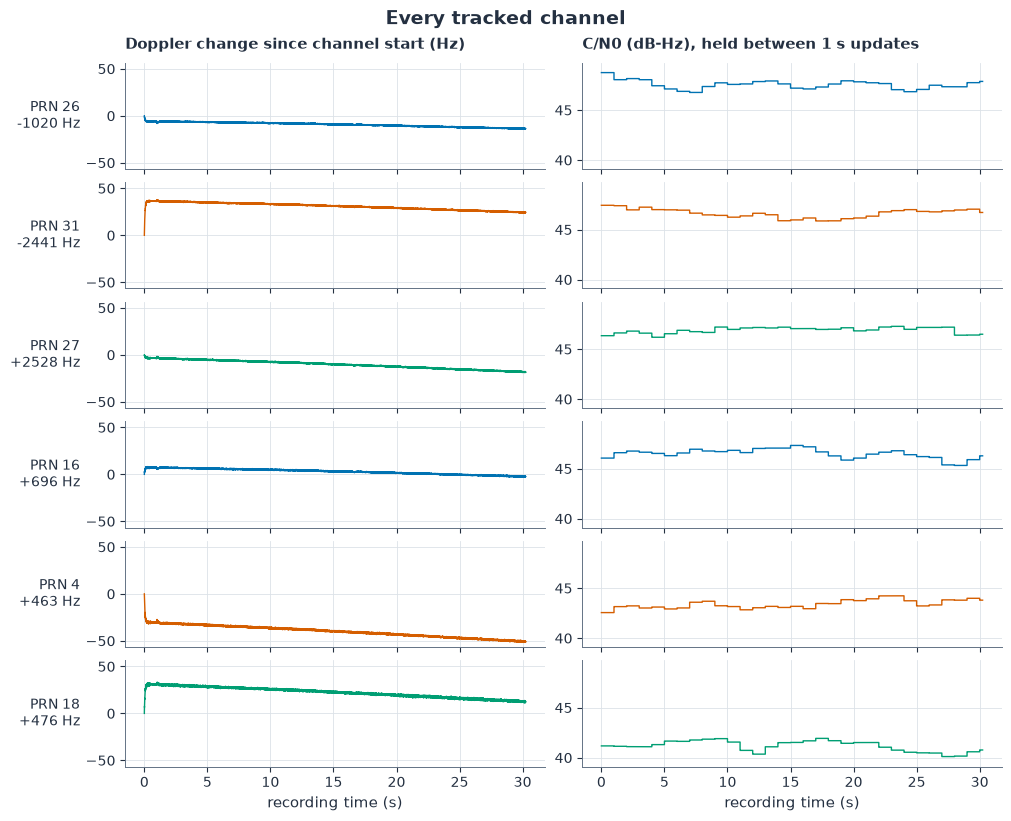

PRN 26: Doppler drift -0.275 Hz/s from 2 s on (least-squares line)


In [10]:
fig, axes = figure(len(tracks), 2, figsize=(10, 1.15 * len(tracks) + 1.2), sharex=True,
                   squeeze=False)  # fmt: skip
spread = max(np.nanmax(np.abs(tr.doppler - tr.doppler[0])) for tr in tracks)
dop_lim = max(1.1 * spread, 1.0)
cn0_lo = min(tr.cn0.min() for tr in tracks) - 1
cn0_hi = max(tr.cn0.max() for tr in tracks) + 1
for i, (tr, (ax_d, ax_c)) in enumerate(zip(tracks, axes)):
    color = LINES[i % len(LINES)]
    ax_d.plot(tr.t, tr.doppler - tr.doppler[0], color=color, linestyle="-", linewidth=1)
    ax_d.set_ylim(-dop_lim, dop_lim)
    ax_d.set_ylabel(f"PRN {tr.prn}\n{tr.doppler[0]:+.0f} Hz", rotation=0, ha="right",
                    va="center", fontsize=10)  # fmt: skip
    ax_c.step(tr.t, tr.cn0, where="post", color=color, linestyle="-", linewidth=1)
    ax_c.set_ylim(cn0_lo, cn0_hi)
axes[0, 0].set_title("Doppler change since channel start (Hz)", fontsize=11)
axes[0, 1].set_title("C/N0 (dB-Hz), held between 1 s updates", fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel("recording time (s)")
fig.suptitle("Every tracked channel")
plt.show()

# how fast the strongest channel's Doppler drifts once the loops have settled
settled = track.t - track.t[0] >= 2.0
slope = np.polyfit(track.t[settled], track.doppler[settled], 1)[0]
print(f"PRN {track.prn}: Doppler drift {slope:+.3f} Hz/s from 2 s on (least-squares line)")

## 4. The navigation message

Tracking produces one prompt sum per code period. To read the message, the receiver
groups those sums into data bits, finds the message boundaries and checks the message
before it trusts the time and orbit it carries. GPS L1 C/A carries the LNAV message at
50 bit/s, so one bit lasts 20 tracking epochs, 20 ms.

Bit synchronization starts 1.5 s after the channel begins: 1 s of FLL pull-in plus 0.5 s
for the PLL to settle. In 2 s windows it counts the sign changes of prompt I at each
epoch position modulo 20. Real bit edges all fall at one position; noise flips the sign
elsewhere at random, and equal neighboring bits give no edge at all. Once one position
clearly wins, the receiver adds the 20 prompt-I values of each bit. With $I_k$ the prompt
I of tracking epoch $k$ and $k_j$ the first epoch of bit $j$, the received bit is

$$
b_j=\begin{cases}1, & \displaystyle\sum_{r=0}^{19} I_{k_j+r}<0,\\ 0, & \text{otherwise.}
\end{cases}
$$

This still leaves the polarity open, because the Costas loop can settle on either sign of
the carrier. Frame synchronization tries the received bits and their complement.

### Words, parity and subframes

A subframe holds ten 30-bit words: the telemetry word (TLM), the handover word (HOW) and
eight data words. Each word carries 24 data bits and 6 parity bits, so a 300-bit
subframe lasts 6 s, and five subframes make a 30 s frame. The TLM starts with the
preamble 10001011.

Parity also depends on the last two transmitted bits of the previous word, called D29*
and D30*. D30* says whether to invert the current word's 24 data bits before reading
them. The parity check combines the recovered data bits with D29* and D30*, computes six
parity bits and compares them with the six received.

One preamble is not enough to trust a boundary. Frame sync needs a second preamble 300
bits later, parity-clean TLM and HOW words, a valid subframe ID and consecutive HOW time
counts. It then checks every word of each complete subframe and drops those with bad
parity or an inconsistent time. Subframe 1 carries the week number and the satellite
clock terms; subframes 2 and 3 carry the orbit, the ephemeris; subframes 4 and 5 carry
almanac and other pages, among them the ionosphere model.

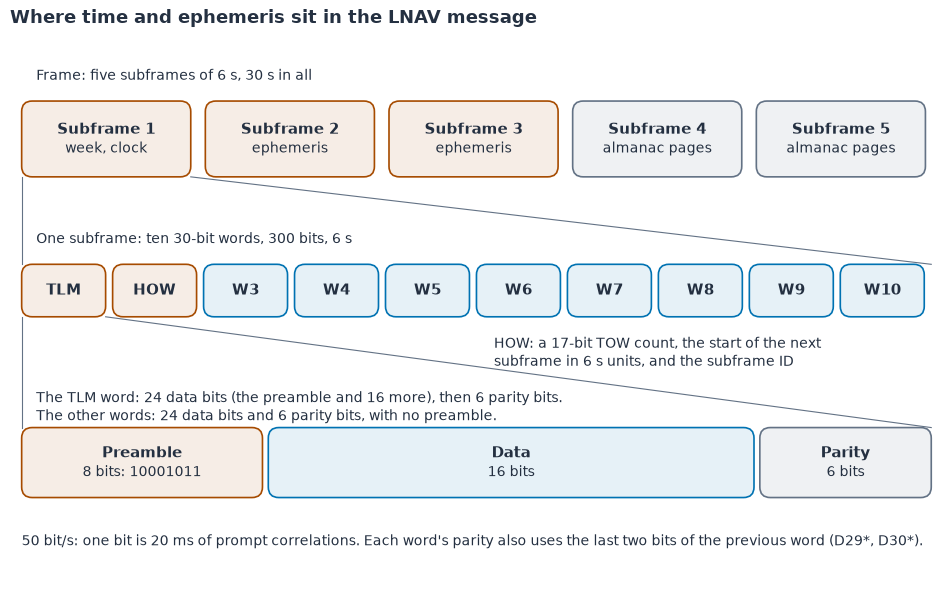

In [11]:
fig, ax = diagram_canvas(16, 9.4, "Where time and ephemeris sit in the LNAV message")
diagram_text(ax, 0.45, 8.75, "Frame: five subframes of 6 s, 30 s in all", size=10, ha="left")
contents = ("week, clock", "ephemeris", "ephemeris", "almanac pages", "almanac pages")
subframes = [
    diagram_box(ax, 0.2 + 3.15 * i, 7.0, 2.9, 1.3, f"Subframe {i + 1}", what,
                role="highlight" if i < 3 else "context")
    for i, what in enumerate(contents)
]  # fmt: skip

words = []
for i in range(10):
    name = "TLM" if i == 0 else "HOW" if i == 1 else f"W{i + 1}"
    words.append(diagram_box(ax, 0.2 + 1.56 * i, 4.6, 1.44, 0.9, name,
                             role="highlight" if i < 2 else "flow"))  # fmt: skip
diagram_text(ax, 0.45, 5.95, "One subframe: ten 30-bit words, 300 bits, 6 s", size=10, ha="left")
# subframe 1 opens out into the word row below it
diagram_line(ax, [subframes[0].at(0, 0), (0.2, 5.5)], width=0.8)
diagram_line(ax, [subframes[0].at(1, 0), (15.8, 5.5)], width=0.8)
diagram_text(
    ax, 8.3, 4.0, "HOW: a 17-bit TOW count, the start of the next\nsubframe in 6 s units, "
    "and the subframe ID", size=10, ha="left",
)  # fmt: skip

y0 = 1.5
diagram_text(
    ax, 0.45, y0 + 1.55, "The TLM word: 24 data bits (the preamble and 16 more), then 6 parity "
    "bits.\nThe other words: 24 data bits and 6 parity bits, with no preamble.", size=10,
    ha="left",
)  # fmt: skip
diagram_line(ax, [words[0].at(0, 0), (0.2, y0 + 1.2)], width=0.8)
diagram_line(ax, [words[0].at(1, 0), (15.8, y0 + 1.2)], width=0.8)
diagram_box(ax, 0.2, y0, 4.13, 1.2, "Preamble", "8 bits: 10001011", role="highlight")
diagram_box(ax, 4.43, y0, 8.33, 1.2, "Data", "16 bits")
diagram_box(ax, 12.86, y0, 2.94, 1.2, "Parity", "6 bits", role="context")
diagram_text(
    ax, 0.2, 0.75, "50 bit/s: one bit is 20 ms of prompt correlations. Each word's parity also "
    "uses the last two bits of the previous word (D29*, D30*).", size=10, ha="left",
)  # fmt: skip
plt.show()

### From a subframe to time tags

The HOW's time count $z$ names the start of the next subframe in units of 6 s. The
decoder subtracts one subframe to store the start of this one:

$$
t_{\rm start}=(6z-6)\bmod W ,
$$

where $W$ = 604 800 s is the length of a GPS week. The TOW (time of week) column of the
table is this start time.

That one time tag dates every tracked code period of the channel. With $k$ a tracking
epoch, $k_0$ the epoch of the subframe's first bit and $T$ = 1 ms,

$$
t_{\rm tx}(k)=t_{\rm start}+(k-k_0)\,T .
$$

In the committed recording, PRN 26's subframe 1 starts at TOW 30270 s at tracking epoch
10488, so epoch 10489 was transmitted at 30270.001 s. The library also checks that all
decoded subframes of a channel agree on this mapping. The week number in subframe 1 is a
10-bit value, 142 here; the library's rollover era adds 2048, giving GPS week 2190. Rows
without a week are subframes that do not carry that field.

The upper plot is one decoded subframe as received, its ten words marked; the lower plot
zooms on the first word. If the channel settled on the other carrier sign, the received
preamble reads as the complement, 01110100; the plot's title says which. The table's last column counts tracking
epochs, about 1 ms each, while the plot counts bits.

The recording decodes subframes 5, 1, 2 and 3 on every tracked channel and no subframe
4, so it gets no ionosphere page. Synthetic data: the signals carry subframes 1, 2 and 3
after a lead-in of 100 zero bits, so this path has no ionosphere page either.

Read more: [Reading the message](../../docs/fundamentals/06-navigation-message.md).

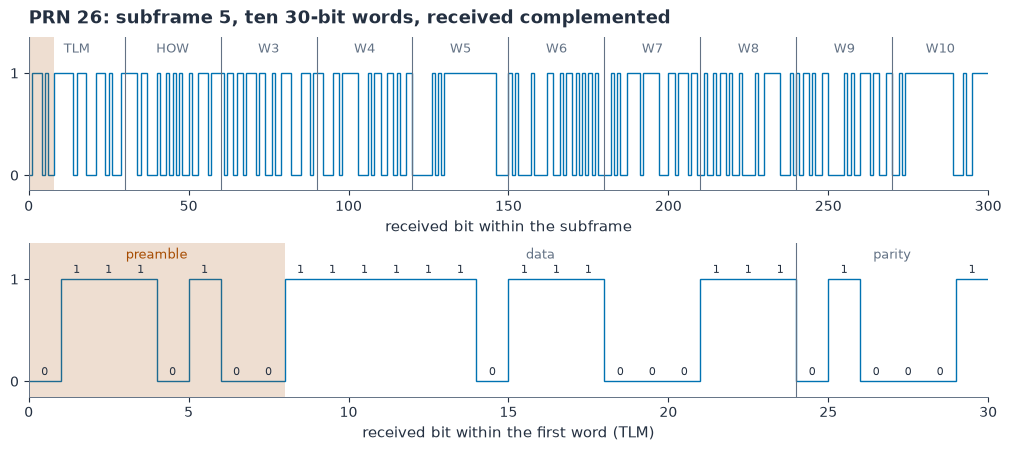

,PRN,subframe,TOW (s),week (mod 1024),first-bit tracking epoch (1 ms)
0,26,5,30264,<NA>,4488
1,26,1,30270,142,10488
2,26,2,30276,<NA>,16488
3,26,3,30282,<NA>,22488
4,31,5,30264,<NA>,4491
5,31,1,30270,142,10491
6,31,2,30276,<NA>,16491
7,31,3,30282,<NA>,22491
8,27,5,30264,<NA>,4490
9,27,1,30270,142,10490


In [12]:
lnavs = [decode_lnav(tr) for tr in tracks]
lnav = lnavs[0]
stream = lnav.stream
# stream.epoch holds each received bit's first tracking epoch: map subframes to bit indices
starts = [int(np.searchsorted(stream.epoch, sf.epoch)) for sf in lnav.subframes]
shown = next(s for s in starts if s + 300 <= len(stream.bits))
sf = lnav.subframes[starts.index(shown)]
bits = stream.bits[shown : shown + 300]
flipped = bits[0] != sf.bits[0]  # received against transmitted polarity

fig, (ax_f, ax_w) = figure(2, 1, figsize=(10, 4.4))
for ax, n in ((ax_f, 300), (ax_w, 30)):
    ax.stairs(bits[:n], np.arange(n + 1), color=LINES[0], linewidth=1, baseline=None)
    ax.axvspan(0, 8, color=HIGHLIGHT, alpha=0.18, linewidth=0)
    ax.set(xlim=(0, n), ylim=(-0.15, 1.35), yticks=[0, 1])
    ax.grid(False)
for w in range(10):
    ax_f.axvline(30 * w, color=MUTED, linewidth=0.8)
    name = "TLM" if w == 0 else "HOW" if w == 1 else f"W{w + 1}"
    ax_f.text(30 * w + 15, 1.2, name, ha="center", fontsize=9, color=MUTED)
ax_w.axvline(24, color=MUTED, linewidth=0.8)
ax_w.text(4, 1.2, "preamble", ha="center", fontsize=9, color=HIGHLIGHT)
ax_w.text(16, 1.2, "data", ha="center", fontsize=9, color=MUTED)
ax_w.text(27, 1.2, "parity", ha="center", fontsize=9, color=MUTED)
for j, b in enumerate(bits[:30]):
    ax_w.text(j + 0.5, b + 0.06 if b else 0.06, str(b), ha="center", fontsize=8, color=INK)
ax_f.set_xlabel("received bit within the subframe")
ax_w.set_xlabel("received bit within the first word (TLM)")
polarity = "complemented" if flipped else "as transmitted"
ax_f.set_title(f"PRN {lnav.prn}: subframe {sf.sf_id}, ten 30-bit words, received {polarity}")
plt.show()

rows = [(ln.prn, s.sf_id, s.tow_s, s.fields.get("wn"), s.epoch)
        for ln in lnavs for s in ln.subframes]  # fmt: skip
week = "week (mod 1024)"
columns = ["PRN", "subframe", "TOW (s)", week, "first-bit tracking epoch (1 ms)"]
pd.DataFrame(rows, columns=columns).astype({week: "Int64"})

### Checking the decoded ephemeris

Passing parity says the bits arrived intact; comparing the decoded fields with an
independent record says they were also read with the right scale factors. For the
recording, the first tracked PRN's ephemeris is set beside the same satellite's record in
the day's broadcast navigation file, matched by PRN and issue of data (IODE) so that both
describe the same orbit update.

The `equal` column compares the full values: floating-point fields with `np.isclose` at a
relative tolerance of 1e-11 (and an absolute one of 1e-30), the others exactly. The
navigation file stores values to 12 decimal places in scientific notation, so this is
agreement at that precision, not a bit-for-bit comparison of the transmitted message. The
values are displayed to 12 significant digits, so the small terms stay visible: the group
delay `tgd` of PRN 26 is 6.98e-9 s and its clock drift `af1` 3.52e-12 s/s. The
navigation file has no field for `aodo`, the age-of-data offset, hence its entry.

Synthetic data: the reference is the ephemeris the signal was generated from, encoded and
decoded by this same library. Agreement shows that the chain from samples to fields is
consistent; it does not compare the decoder with an independent source.

In [13]:
if src is not None:
    nav_ephs, _ = read_rinex_nav(src.recording_nav)
    # match the satellite and its issue of data, not merely the first record for the PRN
    reference = next(e for e in nav_ephs if e.prn == lnav.prn and e.iode == lnav.ephemeris.iode)
    other = "broadcast navigation file"
else:
    reference = synthetic_ephemeris(prn=lnav.prn)
    other = "generating ephemeris"
ours = dataclasses.asdict(lnav.ephemeris)
table = pd.DataFrame({"decoded": ours, other: dataclasses.asdict(reference)})
# navigation values have 12 decimal places in scientific notation; aodo is absent
table["equal"] = [
    "not in RINEX" if name == "aodo" and src is not None
    else bool(np.isclose(a, b, rtol=1e-11, atol=1e-30)) if isinstance(a, float) else a == b
    for name, a, b in zip(table.index, table["decoded"], table[other])
]
table.style.format(
    lambda value: f"{value:.12g}" if isinstance(value, float) else str(value),
    subset=["decoded", other],
)

,decoded,broadcast navigation file,equal
prn,26,26,True
wn,142,142,True
code_l2,1,1,True
ura,0,0,True
health,0,0,True
iodc,54,54,True
l2p,0,0,True
tgd,6.98491930962e-09,6.98491930962e-09,True
toc,36000,36000,True
af2,0,0,True


## 5. Observables

An observable is a measurement the receiver reports. Each channel contributes a
pseudorange, a carrier phase, a Doppler and a C/N0 at common receiver times, 1 s apart.
These observation epochs are not the 1 ms tracking epochs: each one is a single instant
at which every channel is measured.

The channels know transmit times from the navigation message, but the recording has no
accurately set receiver clock. The library gives all channels one time origin at sample
0: the latest transmit time extrapolated to sample 0, plus a nominal 68 ms, rounded to
1 ms. Taking the latest transmission puts the shortest apparent travel time near that
nominal value, and 68 ms × c ≈ 20 400 km, about the distance to a GPS satellite overhead.
Any error in this choice adds the same clock offset to every pseudorange of an epoch,
and the position solution of notebook 02 estimates it along with the position.

To form an observation at receiver time $t_{\rm rx}$, take the two code starts of a
channel that bracket that instant. Let $u$ be the instant in seconds from the start of
the recording, $u_k$ and $u_{k+1}$ the bracketing code starts on that sample clock, and
$t_{\rm tx}(k)$ the transmit time of code start $k$. The fraction

$$
\alpha=\frac{u-u_k}{u_{k+1}-u_k}
$$

places the instant between them. The next code start was transmitted $T$ = 1 ms later,
so

$$
t_{\rm tx}=t_{\rm tx}(k)+\alpha T,\qquad P=c\,(t_{\rm rx}-t_{\rm tx}),
$$

with $c$ the speed of light and $P$ the pseudorange in meters. It is a pseudorange
because the two times are read on different clocks, the receiver's and the satellite's,
and the path is longer than the straight line. A model of what it contains is

$$
P=\rho+c\,(\mathrm{dt}_r-\mathrm{dt}^s)+I+T_{\rm trop}+\eta_P .
$$

Here $\rho$ is the geometric range (including a small correction for the Earth's rotation
during the signal's flight), $\mathrm{dt}_r$ and $\mathrm{dt}^s$ the receiver and
satellite clock biases in seconds, $I$ and $T_{\rm trop}$ the ionospheric and
tropospheric delays in meters, and $\eta_P$ the noise and everything else this simple model
leaves out. (The shared notation writes the tropospheric delay as $T$; here $T$ is
already the code period.) This notebook forms the measurement; notebook 02 models the
terms to solve for a position.

In the diagram, the decoded subframe dates one code period of a channel, and counting
periods dates the rest. At each shared receiver instant every channel's transmit time is
interpolated between its own code starts, so all pseudoranges of an epoch carry the same
receiver clock error.

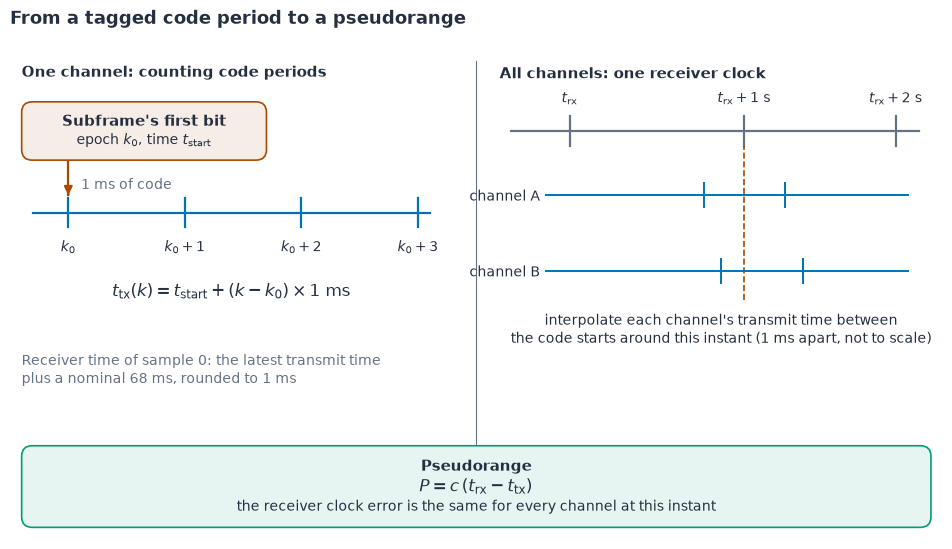

In [14]:
fig, ax = diagram_canvas(16, 8.6, "From a tagged code period to a pseudorange")
# left: one channel's code periods, dated from a decoded subframe
diagram_text(ax, 0.2, 8.0, "One channel: counting code periods", size=11,
             ha="left", fontweight="bold")  # fmt: skip
y = 5.6
diagram_line(ax, [(0.4, y), (7.2, y)], role="flow", width=1.6)
for i, x in enumerate((1.0, 3.0, 5.0, 7.0)):
    diagram_line(ax, [(x, y - 0.25), (x, y + 0.25)], role="flow", width=1.6)
    diagram_text(ax, x, y - 0.6, r"$k_0$" if i == 0 else rf"$k_0+{i}$", size=10)
diagram_text(ax, 2.0, y + 0.5, "1 ms of code", size=10, color=MUTED)
first = diagram_box(ax, 0.2, 6.5, 4.2, 1.0, "Subframe's first bit", r"epoch $k_0$, time $t_{\rm start}$",
                    role="highlight")  # fmt: skip
diagram_arrow(ax, [(1.0, first.y), (1.0, y + 0.3)], role="highlight")
diagram_text(ax, 3.8, 4.25, r"$t_{\rm tx}(k)=t_{\rm start}+(k-k_0)\times 1\ {\rm ms}$", size=12)

diagram_line(ax, [(8.0, 1.6), (8.0, 8.2)], width=0.8)

# right: every channel sampled at one receiver instant
diagram_text(ax, 8.4, 8.0, "All channels: one receiver clock", size=11, ha="left",
             fontweight="bold")  # fmt: skip
diagram_line(ax, [(8.6, 7.0), (15.6, 7.0)], role="context", width=1.6)
for x, name in ((9.6, r"$t_{\rm rx}$"), (12.6, r"$t_{\rm rx}+1$ s"), (15.2, r"$t_{\rm rx}+2$ s")):
    diagram_line(ax, [(x, 6.75), (x, 7.25)], role="context", width=1.6)
    diagram_text(ax, x, 7.55, name, size=10)
diagram_line(ax, [(12.6, 4.1), (12.6, 6.75)], role="highlight", dashed=True, width=1.2)
for yy, name, ticks in ((5.9, "channel A", (11.9, 13.3)), (4.6, "channel B", (12.2, 13.6))):
    diagram_line(ax, [(9.2, yy), (15.4, yy)], role="flow", width=1.4)
    diagram_text(ax, 9.1, yy, name, size=10, ha="right")
    for x in ticks:
        diagram_line(ax, [(x, yy - 0.2), (x, yy + 0.2)], role="flow", width=1.4)
diagram_text(ax, 12.2, 3.9, "interpolate each channel's transmit time between\nthe code starts "
             "around this instant (1 ms apart, not to scale)", size=10, va="top")  # fmt: skip

result = diagram_box(
    ax, 0.2, 0.2, 15.6, 1.4, "Pseudorange", "the receiver clock error is the same for every "
    "channel at this instant", formula=r"$P=c\,(t_{\rm rx}-t_{\rm tx})$", role="measure",
)  # fmt: skip
diagram_text(
    ax, 0.2, 2.9, "Receiver time of sample 0: the latest transmit time\nplus a nominal 68 ms, "
    "rounded to 1 ms", size=10, ha="left", color=MUTED,
)  # fmt: skip
plt.show()

### Carrier phase, Doppler and loss of lock

The carrier phase counts the replica carrier's accumulated cycles. Let $A$ be the
accumulated Doppler phase of the channel, interpolated to the observation instant, and
$h$ half a cycle when the decoded data polarity shows the carrier was followed with
inverted sign, zero otherwise. The phase written out, in cycles, is

$$
\varphi=-(A+h) .
$$

The minus sign is the RINEX convention: the phase decreases while the satellite
approaches. The half cycle resolves which data sign the Costas loop locked to. Neither
reveals the whole number of wavelengths that were already on the path when counting
began. That integer is the carrier ambiguity $N$. With the L1 wavelength
$\lambda=c/f_{L1}\approx 0.1903$ m, the phase as a length is $\Phi=\lambda\varphi$, offset
by an unknown $N\lambda$. Continuous tracking keeps the count; a cycle slip breaks it.
Notebook 03 deals with $N$.

The Doppler $f_D$ is the carrier offset the tracker followed, positive while the
satellite approaches. With the phase's sign, $f_D\approx-d\varphi/dt$ while the
polarity stays fixed. Both contain the front-end oscillator's frequency error, and the
pseudorange's slope contains the receiver clock's drift, so none of them is the pure
geometric range rate.

The loss-of-lock indicator (LLI) marks carrier phases whose continuity is in doubt,
using two bits:

- Value 1 marks observations within the first 2 s of a channel, the boundary included,
  and the first observation after a detected change of data polarity.
- Value 2 marks a half-cycle polarity that is not yet resolved: before the channel's
  first decoded subframe, and between the end of a subframe on one polarity and the
  start of the first subframe on the other.

Both can be set at once, giving 3. The startup rule counts the channel's running time,
so a channel's first observation after 2 s carries no value 1.

The first figure gives each satellite's pseudorange at the first epoch and its change
since. In the committed recording the pseudoranges differ by up to about 2 200 km
between satellites, and over 27 s they change by up to about 13 km. The second checks the
phase against the Doppler for one channel and counts the flagged observations at each
epoch. In the committed recording no observation carries value 1, since every channel has
run for longer than 2 s by the first epoch. All six carry value 2 at the first three
epochs: those come before each channel's first decoded subframe (subframe 5, which starts
at TOW 30264 s, 08:24:24 GPS time), because the time tags count back from a decoded
subframe as well as forward. Synthetic data: the first observation of every channel
carries both values; it falls within the channel's first 2 s.

Read more: [The measurements](../../docs/fundamentals/07-measurements.md).

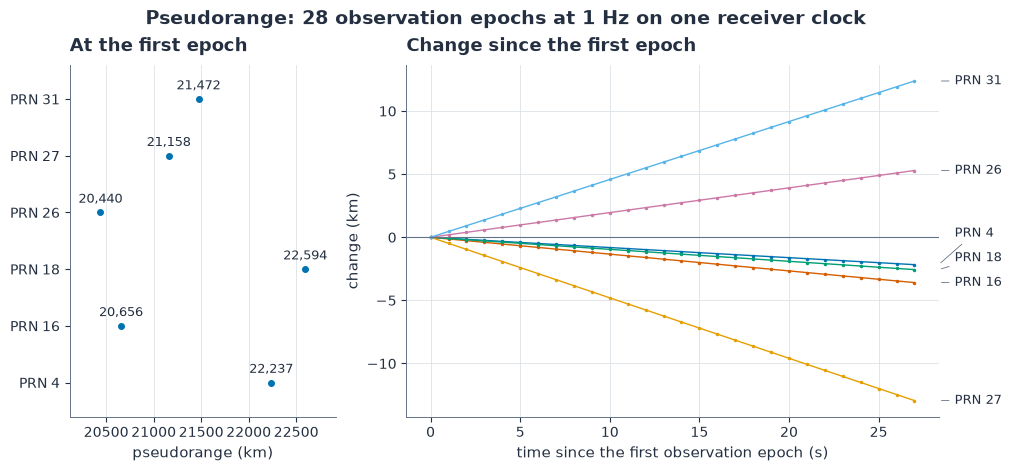

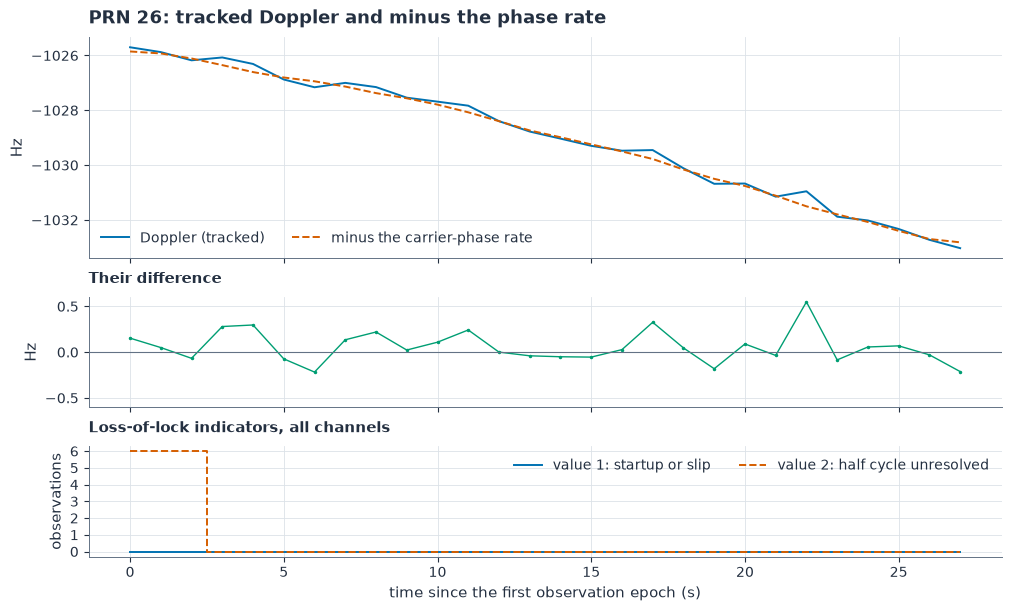

In [15]:
# one receiver-time grid shared by every usable channel
epochs = make_observables(tracks, lnavs)
t_rel = np.array([e.tow - epochs[0].tow for e in epochs])
prns = sorted({o.prn for e in epochs for o in e.obs})


def series(prn, field):
    return np.array([next((getattr(o, field) for o in e.obs if o.prn == prn), np.nan)
                     for e in epochs])  # fmt: skip


def end_labels(ax, values, names, gap=0.07):
    # right-gutter labels at each line's last value, spread so they do not overlap
    lo, hi = ax.get_ylim()
    order = np.argsort(values)
    ys = [(values[i] - lo) / (hi - lo) for i in order]
    for j in range(1, len(ys)):
        ys[j] = max(ys[j], ys[j - 1] + gap)
    shift = max(ys[-1] - 0.97, 0)
    for i, y in zip(order, ys):
        ax.annotate(names[i], (1.0, (values[i] - lo) / (hi - lo)), xycoords="axes fraction",
                    xytext=(1.03, y - shift), textcoords="axes fraction", va="center",
                    fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.6})


first_p = np.array([series(prn, "pseudorange")[0] for prn in prns])
fig, (ax_a, ax_r) = figure(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1, 2]})
ax_a.plot(first_p / 1e3, range(len(prns)), "o", color=LINES[0])
for i, p in enumerate(first_p):
    ax_a.annotate(f"{p / 1e3:,.0f}", (p / 1e3, i), xytext=(0, 7), textcoords="offset points",
                  ha="center", fontsize=9)  # fmt: skip
ax_a.set_yticks(range(len(prns)), [f"PRN {prn}" for prn in prns])
ax_a.margins(x=0.15, y=0.12)
ax_a.set(xlabel="pseudorange (km)")
ax_a.grid(axis="y", visible=False)
ax_a.set_title("At the first epoch")
ends = []
for i, prn in enumerate(prns):
    change = series(prn, "pseudorange") - first_p[i]
    ax_r.plot(t_rel, change / 1e3, ".-", linewidth=1, markersize=3)
    ends.append(change[np.isfinite(change)][-1] / 1e3)
ax_r.axhline(0, color=MUTED, linewidth=0.8)
ax_r.set(xlabel="time since the first observation epoch (s)", ylabel="change (km)")
end_labels(ax_r, np.array(ends), [f"PRN {prn}" for prn in prns])
ax_r.set_title("Change since the first epoch")
fig.suptitle(f"Pseudorange: {len(epochs)} observation epochs at 1 Hz on one receiver clock")
plt.show()

prn = tracks[0].prn
L, D = series(prn, "carrier_phase"), series(prn, "doppler")
rate = -np.gradient(L, t_rel)  # numerical phase rate, one-sided at the two ends
fig, (ax_d, ax_e, ax_s) = figure(3, 1, figsize=(10, 6.0), sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1, 1]})  # fmt: skip
ax_d.plot(t_rel, D, color=LINES[0], linestyle="-", label="Doppler (tracked)")
ax_d.plot(t_rel, rate, color=LINES[1], linestyle="--", label="minus the carrier-phase rate")
ax_d.set_ylabel("Hz")
ax_d.ticklabel_format(axis="y", useOffset=False)
ax_d.legend(loc="lower left", ncol=2)
ax_d.set_title(f"PRN {prn}: tracked Doppler and minus the phase rate")
residual = D - rate
ax_e.plot(t_rel, residual, ".-", color=LINES[2], linewidth=1, markersize=3)
ax_e.axhline(0, color=MUTED, linewidth=0.8)
span = max(1.1 * np.nanmax(np.abs(residual)), 0.05)
ax_e.set(ylim=(-span, span), ylabel="Hz")
ax_e.set_title("Their difference", fontsize=11)
# count the observations of each epoch carrying each LLI bit
for bit, name, color, style in ((1, "value 1: startup or slip", LINES[0], "-"),
                                (2, "value 2: half cycle unresolved", LINES[1], "--")):
    count = [sum(bool(o.lli & bit) for o in e.obs) for e in epochs]
    ax_s.step(t_rel, count, where="mid", color=color, linestyle=style, label=name)
ax_s.yaxis.set_major_locator(MaxNLocator(integer=True))
ax_s.set_ylim(bottom=-0.3)
ax_s.set(xlabel="time since the first observation epoch (s)", ylabel="observations")
ax_s.legend(loc="upper right", ncol=2)
ax_s.set_title("Loss-of-lock indicators, all channels", fontsize=11)
plt.show()

## 6. RINEX

RINEX is the text format for exchanging receiver measurements and satellite navigation
data. The cell below writes `pyrx.obs` and `pyrx.nav`, both RINEX 3.05, to the notebook's
temporary directory and prints the first 25 lines of each.

In the observation header, `G` means GPS, and the observation types are listed in the
order they appear on each satellite's line:

- `C1C`: L1 C/A pseudorange, in meters.
- `L1C`: carrier phase, in cycles, followed by its LLI digit.
- `D1C`: Doppler, in hertz.
- `S1C`: C/N0, in dB-Hz.

`APPROX POSITION XYZ` holds zeros because this writer does not supply an approximate
station position; nothing has computed one yet. The `PGM / RUN BY / DATE` line records
when the file was written, in UTC, while `TIME OF FIRST OBS` is the time of the first
measurement, in GPS time.

An epoch block starts with `>`, the receiver's GPS date and time, the epoch flag and the
number of satellites. In the committed output the first block is at 08:24:22 with flag 0
and six satellites. The G04 line reads 22236668.717 m, −1046.556 cycles, +431.529 Hz and
43.228 dB-Hz; the 2 that follows −1046.556 is the LLI digit (value 2, half cycle
unresolved), not another decimal place of the phase.

The navigation file stores the decoded clock and orbit parameters. The first record in the
committed output is G26. Its first line gives the clock reference time, 10:00 GPS time,
then the clock terms af0, af1 and af2: offset in seconds, drift in seconds per second and
drift rate in seconds per second squared. For this record the IODE is 54, the ephemeris
reference time 36000 s, the GPS week 2190 and the transmission time 30270 s, the
subframe-1 start decoded above. The seven continuation lines hold the orbit parameters and
their supporting fields, among them the IODE, the ephemeris reference time, the health,
the group delay and the transmission time. The header carries no ionosphere coefficients,
because neither data path decoded the page that holds them.

On the capture path the positioning notebooks read RINEX files in these same formats,
from public reference stations that recorded for hours, rather than the short files
written here. On the synthetic path they build their observations in memory.

In [16]:
obs_path, nav_path = out / "pyrx.obs", out / "pyrx.nav"
write_rinex_obs(obs_path, epochs)
ephs = [ln.ephemeris for ln in lnavs if ln.ephemeris is not None]
tow1 = {ln.prn: s.tow_s for ln in lnavs for s in ln.subframes if s.sf_id == 1}
# ionosphere coefficients only if a decoded channel supplied that page
iono = next((ln.ionosphere for ln in lnavs if ln.ionosphere is not None), None)
write_rinex_nav(nav_path, ephs, tow1, iono)
for p in (obs_path, nav_path):
    print(f"==> {p.name}")
    print("\n".join(p.read_text().splitlines()[:25]))
    print()

==> pyrx.obs
     3.05           OBSERVATION DATA    G: GPS              RINEX VERSION / TYPE
pyrx                                    20261029 165514 UTC PGM / RUN BY / DATE
PYRX                                                        MARKER NAME
                                                            OBSERVER / AGENCY
                    pyrx                                    REC # / TYPE / VERS
                                                            ANT # / TYPE
        0.0000        0.0000        0.0000                  APPROX POSITION XYZ
        0.0000        0.0000        0.0000                  ANTENNA: DELTA H/E/N
G    4 C1C L1C D1C S1C                                      SYS / # / OBS TYPES
  2021    12    26     8    24   22.0000000     GPS         TIME OF FIRST OBS
G L1C                                                       SYS / PHASE SHIFT
                                                            END OF HEADER
> 2021 12 26 08 24 22.0000000  0  6
G04  22236668.71

## 7. Comparison with Pocket SDR

Pocket SDR is another GNSS software receiver, and its two trackers processed the same
recording. Its Python tracker logs every channel every 0.1 s, starting at 0.100 s; its C
tracker logs once a second, with the transmit time of week. The differences below are
Pocket SDR minus `pyrx`, the order used for every comparison in these notebooks.

The first figure sets `pyrx`'s acquisition results beside the first values the Python
tracker logged. These come from different stages: acquisition sums ten short correlations
over 500 Hz Doppler bins and interpolates between them, while Pocket SDR's first log row
has already been through 0.1 s of tracking. In the committed recording the C/N0 values
agree to within a few tenths of a dB. The Doppler differs by a few to a few tens of hertz
for most PRNs and by about +107 Hz for PRN 29. The largest of the others, PRN 31, 18 and
4, are the channels whose FLL moved the Doppler by some 30 Hz in the same direction during
pull-in (section 3). The figure includes PRN 29, which the six-channel selection above
left untracked.

The C/N0 panel follows PRN 26 in the committed recording. The two start together; after
that Pocket SDR reports the higher value, by up to about 2 dB, and the separation varies
with time.

The timing rows compare transmit times at the C tracker's log instants. `pyrx`'s code
starts fall between those instants, so its transmit-time tags are interpolated to the same
sample-clock times before the subtraction, and Pocket SDR's logged code offset is removed
from its time tag. The receivers write their output on different schedules, and this way
the comparison is at the same instant. The shaded band is ±20 ns, about 6 m of light
travel and less than half of a 41.7 ns sample at 24 MHz. In the committed recording every
difference stays inside the band: they sit about 6 to 16 ns below zero for every
satellite, a common offset well inside it. The rows start late because the C tracker marks
its transmit times valid only from about 17 s into the recording (23 s for two of the
channels). The agreement checks the timing chain and its interpolation over the interval
both receivers cover; the position accuracy is measured in notebook 02.

Synthetic data: there are no Pocket SDR logs of the generated recording, so the cell
prints a note instead of the figures.

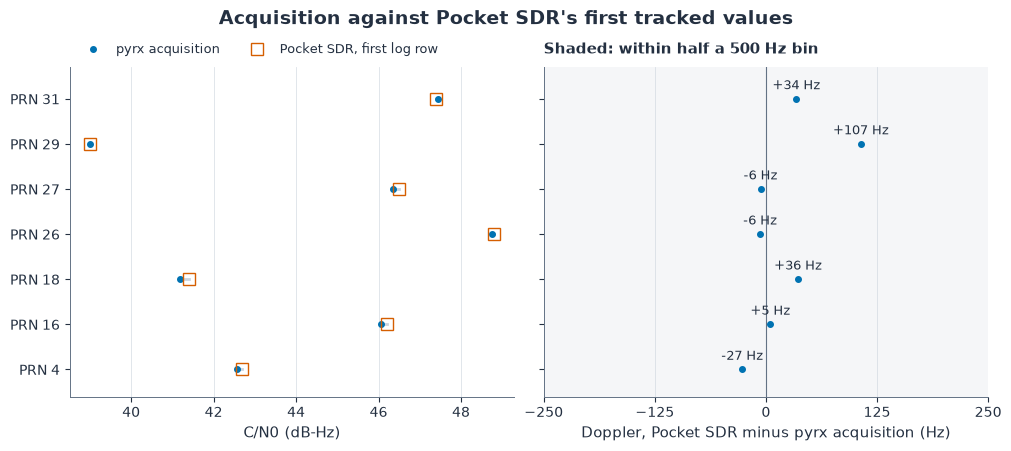

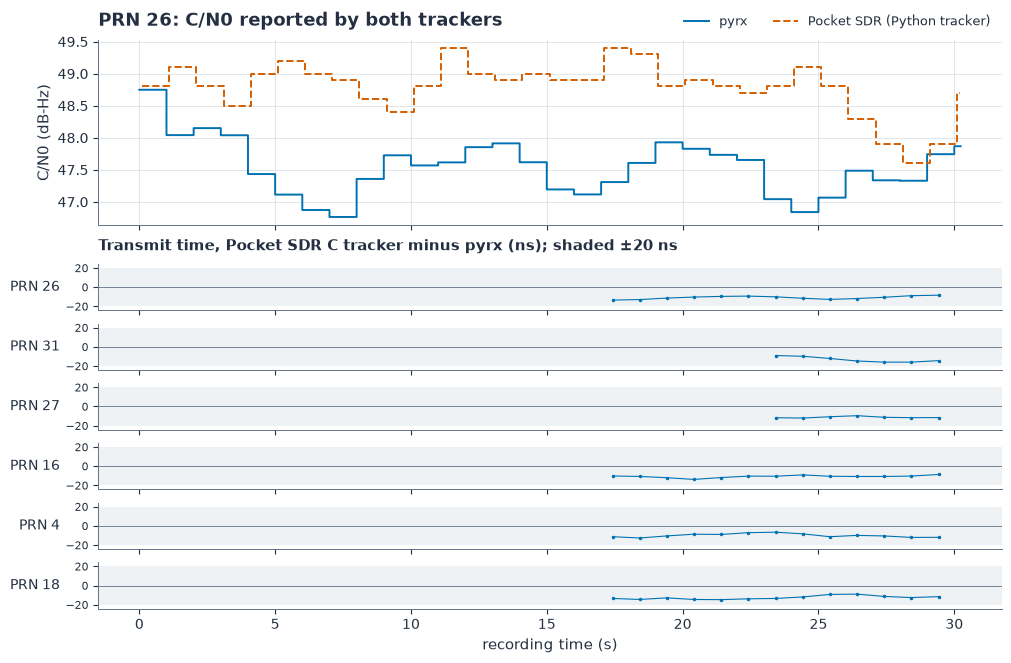

In [17]:
if src is None:
    print("Synthetic data: comparison skipped (no external reference data).")
else:
    trk = read_trk_log(src.trk_log)
    ctrk = read_ctrk_log(src.ctrk_log)
    common = sorted((r for r in detected if r.prn in trk), key=lambda r: r.prn)
    rows_y = np.arange(len(common))
    fig, (ax_c, ax_d) = figure(1, 2, figsize=(10, 4.4), sharey=True)
    for y, r in zip(rows_y, common):
        ax_c.plot([r.cn0, trk[r.prn][0, 1]], [y, y], color=BAR, linestyle="-", linewidth=2)
    ax_c.plot([r.cn0 for r in common], rows_y, "o", color=LINES[0], label="pyrx acquisition")
    ax_c.plot([trk[r.prn][0, 1] for r in common], rows_y, "s", color=LINES[1], markersize=8,
              markerfacecolor="none", label="Pocket SDR, first log row")  # fmt: skip
    ax_c.set_yticks(rows_y, [f"PRN {r.prn}" for r in common])
    ax_c.set_ylim(-0.6, len(common) - 0.3)
    ax_c.set(xlabel="C/N0 (dB-Hz)")
    ax_c.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
    ax_c.grid(axis="y", visible=False)
    dd = np.array([trk[r.prn][0, 3] - r.doppler for r in common])
    lim = max(250.0, 1.1 * np.abs(dd).max())
    ax_d.axvspan(-250, 250, color=BAR, alpha=0.2, linewidth=0)
    ax_d.axvline(0, color=MUTED, linewidth=0.8)
    ax_d.plot(dd, rows_y, "o", color=LINES[0])
    for y, v in zip(rows_y, dd):
        ax_d.annotate(f"{v:+.0f} Hz", (v, y), xytext=(0, 7), textcoords="offset points",
                      ha="center", fontsize=9)  # fmt: skip
    ax_d.set(xlim=(-lim, lim), xticks=[-250, -125, 0, 125, 250],
             xlabel="Doppler, Pocket SDR minus pyrx acquisition (Hz)")  # fmt: skip
    ax_d.set_title("Shaded: within half a 500 Hz bin", fontsize=11)
    ax_d.grid(axis="y", visible=False)
    fig.suptitle("Acquisition against Pocket SDR's first tracked values")
    plt.show()

    # transmit times at the C tracker's log instants, Pocket SDR minus pyrx
    timing = []
    for tr, ln in zip(tracks, lnavs):
        if tr.prn not in ctrk or ln.stream is None:
            continue
        rows = ctrk[tr.prn]
        rows = rows[rows[:, 5] > 0]  # C-tracker rows whose transmit time is valid
        tc, tt = code_starts(tr), transmit_times(tr, ln)
        t = rows[:, 0]
        inside = (t >= tc[ln.stream.epoch[0]]) & (t < tc[-1])  # both receivers have times
        t = t[inside]
        k = np.searchsorted(tc, t, side="right") - 1  # the code starts bracketing each log time
        # interpolate our transmit time between those code starts
        ours = tt[k] + (t - tc[k]) / (tc[k + 1] - tc[k]) * 1e-3
        # the C tracker's code-start time tag less its logged code offset
        theirs = (rows[inside, 6] - rows[inside, 2]) * 1e-3
        timing.append((tr.prn, t, (theirs - ours) * 1e9))

    prn = track.prn
    fig, axes = figure(1 + len(timing), 1, figsize=(10, 2.8 + 0.62 * len(timing)), sharex=True,
                       gridspec_kw={"height_ratios": [2.5] + [0.62] * len(timing)})  # fmt: skip
    ax_n = axes[0]
    ax_n.step(track.t, track.cn0, where="post", color=LINES[0], linestyle="-", label="pyrx")
    ax_n.step(trk[prn][:, 0], trk[prn][:, 1], where="post", color=LINES[1], linestyle="--",
              label="Pocket SDR (Python tracker)")  # fmt: skip
    ax_n.set_ylabel("C/N0 (dB-Hz)")
    ax_n.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2, fontsize=9)
    ax_n.set_title(f"PRN {prn}: C/N0 reported by both trackers")
    for ax, (p, t, diff) in zip(axes[1:], timing):
        ax.axhspan(-20, 20, color=BAR, alpha=0.3, linewidth=0)
        ax.axhline(0, color=MUTED, linewidth=0.6)
        ax.plot(t, diff, ".-", color=LINES[0], linewidth=0.8, markersize=3)
        top = max(24.0, 1.1 * np.abs(diff).max())
        ax.set(ylim=(-top, top), yticks=[-20, 0, 20])
        ax.set_ylabel(f"PRN {p}", rotation=0, ha="right", va="center", fontsize=10)
        ax.tick_params(axis="y", labelsize=8)
        ax.grid(False)
    axes[1].set_title("Transmit time, Pocket SDR C tracker minus pyrx (ns); shaded ±20 ns",
                      fontsize=11)  # fmt: skip
    axes[-1].set_xlabel("recording time (s)")
    plt.show()

## From measurements to a position

Acquisition supplied a rough code offset and Doppler for each satellite. Tracking refined
both and kept a continuous count of the carrier, and the decoded message attached a
transmit time to each code period. One receiver clock for all channels then turned those
times into pseudoranges, with the carrier phase alongside, and the RINEX files hold the
result.

In the committed recording seven PRNs pass the 38 dB-Hz acquisition threshold and the
notebook tracks the strongest six; the transmit times agree with Pocket SDR's C tracker
inside the 20 ns band. Synthetic data: the four generated signals run through the same
stages without a comparison.

[Notebook 02: standalone positioning](02-standalone-pvt.ipynb) takes observations and
navigation data like these (read from a public station's RINEX files on the capture
path, generated in memory otherwise), computes the satellite positions, models the
delays left in the pseudoranges and solves for the receiver's position and clock error.